# Was It the Player or the Team?
## Building a Bayesian skill model for soccer, live in PyMC

> [Alexandre Andorra](https://alexandorra.github.io/), [Carnegie Mellon Sports Analytics Conference](https://www.stat.cmu.edu/cmsac/conference/), October 2026

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlexAndorra/cmsac-2026/blob/main/player_or_team.ipynb)

Welcome! This notebook is designed to be run cell by cell as we go. No need to rush, and ask questions anytime.

**What we'll build today:**
1. A Bayesian model for player goal-scoring ability
2. Gaussian processes to capture how scoring evolves over time, within a season and across seasons
3. A factor model that separates *individual skill* from *team effects*
4. And then the question that matters most: does it actually predict anything?

All with real data, real uncertainty, and real decisions. Everything here comes from the [Soccer Factor Model](https://www.soccerfactormodel.com), which Maximilian Göbel and I developed ([paper](https://arxiv.org/abs/2412.05911)).

---
# Part 0 — Setup

In [1]:
import sys

if "google.colab" in sys.modules:  # local users: `uv sync` in the repo gives the same pinned stack
    %pip install -q "pymc==6.3.2" "pytensor==3.3.4" "nutpie==0.16.11" "arviz==1.3.0" "arviz-base==1.3.1" "arviz-stats==1.3.3" "arviz-plots==1.3.2" "preliz==0.28.0"

> If Colab shows a **"Restart session"** banner after the install cell, click it, then `Runtime → Run all` once more. It happens at most once.

In [2]:
import warnings
from pathlib import Path

import arviz as az
import arviz_plots as azp
import arviz_stats as azs
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import preliz as pz
import pymc as pm
import statsmodels.api as sm
import xarray as xr
from scipy import stats
from scipy.special import expit, logit
from sklearn.metrics import brier_score_loss
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning, module="arviz_plots")  # xarray deprecation noise
az.style.use("arviz-variat")
az.rcParams["stats.ci_prob"] = 0.94  # credible intervals: 94% HDI
az.rcParams["stats.ci_kind"] = "hdi"
plt.rcParams["figure.figsize"] = [12, 5]
plt.rcParams["legend.fontsize"] = 11
%config InlineBackend.figure_format = "retina"

# Reproducible, descriptive seed (not a magic number)
RANDOM_SEED = sum(map(ord, "player-or-team"))
rng = np.random.default_rng(RANDOM_SEED)


def sampler_kwargs(draws=1000, tune=1000, target_accept=0.9):
    """NUTS via nutpie, with low-rank mass-matrix adaptation. Chains: the sampler's default"""
    return dict(
        nuts_sampler="nutpie",
        nuts={"adaptation": "low_rank", "target_accept": target_accept},
        draws=draws,
        tune=tune,
        random_seed=rng,
    )


print(
    f"PyMC {pm.__version__} · nutpie {nutpie.__version__} · ArviZ {az.__version__} · arviz-plots {azp.__version__} · arviz-stats {azs.__version__} · preliz {pz.__version__}"
)

PyMC 6.3.2 · nutpie 0.16.11 · ArviZ 1.3.0 · arviz-plots 1.3.2 · arviz-stats 1.3.3 · preliz 0.28.0


We'll sample every model with [nutpie](https://pymc-devs.github.io/nutpie/), using its **low-rank mass-matrix adaptation**: during tuning, the sampler learns not only how wide each parameter's posterior is, but also the strongest correlations between parameters. Hierarchical models are full of those (each player's skill vs the average across players, for instance), so that's our default from now on. More about it in [this LBS episode](https://learnbayesstats.com/episode/faster-sampling-mass-matrix-adaptation-hmc-nutpie-seyboldt-carlson).

---
# Part 1 — Why Bayes?

## The Motivating Question

Imagine you're watching the World Cup. The French striker ended the tournament with 10 goals, while the one from Cabo Verde scored 4.

**Who is actually better?**

Raw stats mix up *individual talent* with *team strength*, *system*, and *opportunity*. Answering properly means building a model that can imagine a world that never happened: one where both players wore the same shirt.

And when a wrong signing can cost €50M+, decision-makers need **clarity with calibrated uncertainty**, not just a point estimate.

## Bayesian Thinking in 60 Seconds

The Bayesian workflow is simple:

1. **Prior**: What do we believe *before* seeing data? ("Most strikers score in a minority of their matches")
2. **Likelihood**: How does our model generate data? ("Each appearance is a Bernoulli trial")
3. **Posterior**: What do we believe *after* seeing data? (Updated beliefs with uncertainty)

$$\underbrace{P(\theta | \text{data})}_{\text{posterior}} \propto \underbrace{P(\text{data} | \theta)}_{\text{likelihood}} \times \underbrace{P(\theta)}_{\text{prior}}$$

The key insight: **the posterior is a full distribution**, not a single number. It tells you not just "what's most likely" but "how sure should I be?"

## Live Demo: How Certain Should You Be?

Let's say a new signing has scored in 3 of his first 8 appearances. What's his true scoring rate?

A frequentist says: 3/8 = 37.5%. Done.

A Bayesian says: well, it depends... let me show you.

In [3]:
# observed: scored in 3 of his first 8 appearances
n_appearances = 8
n_goals = 3

with pm.Model() as simple_model:
    # prior: what do we know about strikers in general? Most score in 5-25% of their matches
    scoring_rate = pm.Beta("scoring_rate", alpha=2, beta=10)

    # likelihood: each appearance is a coin flip (with a biased coin)
    pm.Binomial("goals", n=n_appearances, p=scoring_rate, observed=n_goals)

    simple_trace = pm.sample(**sampler_kwargs())
    simple_trace.update(pm.sample_prior_predictive(random_seed=rng))

azs.diagnose(simple_trace);

NUTS[nutpie]: [scoring_rate]


Output()

Sampling: [goals, scoring_rate]


Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


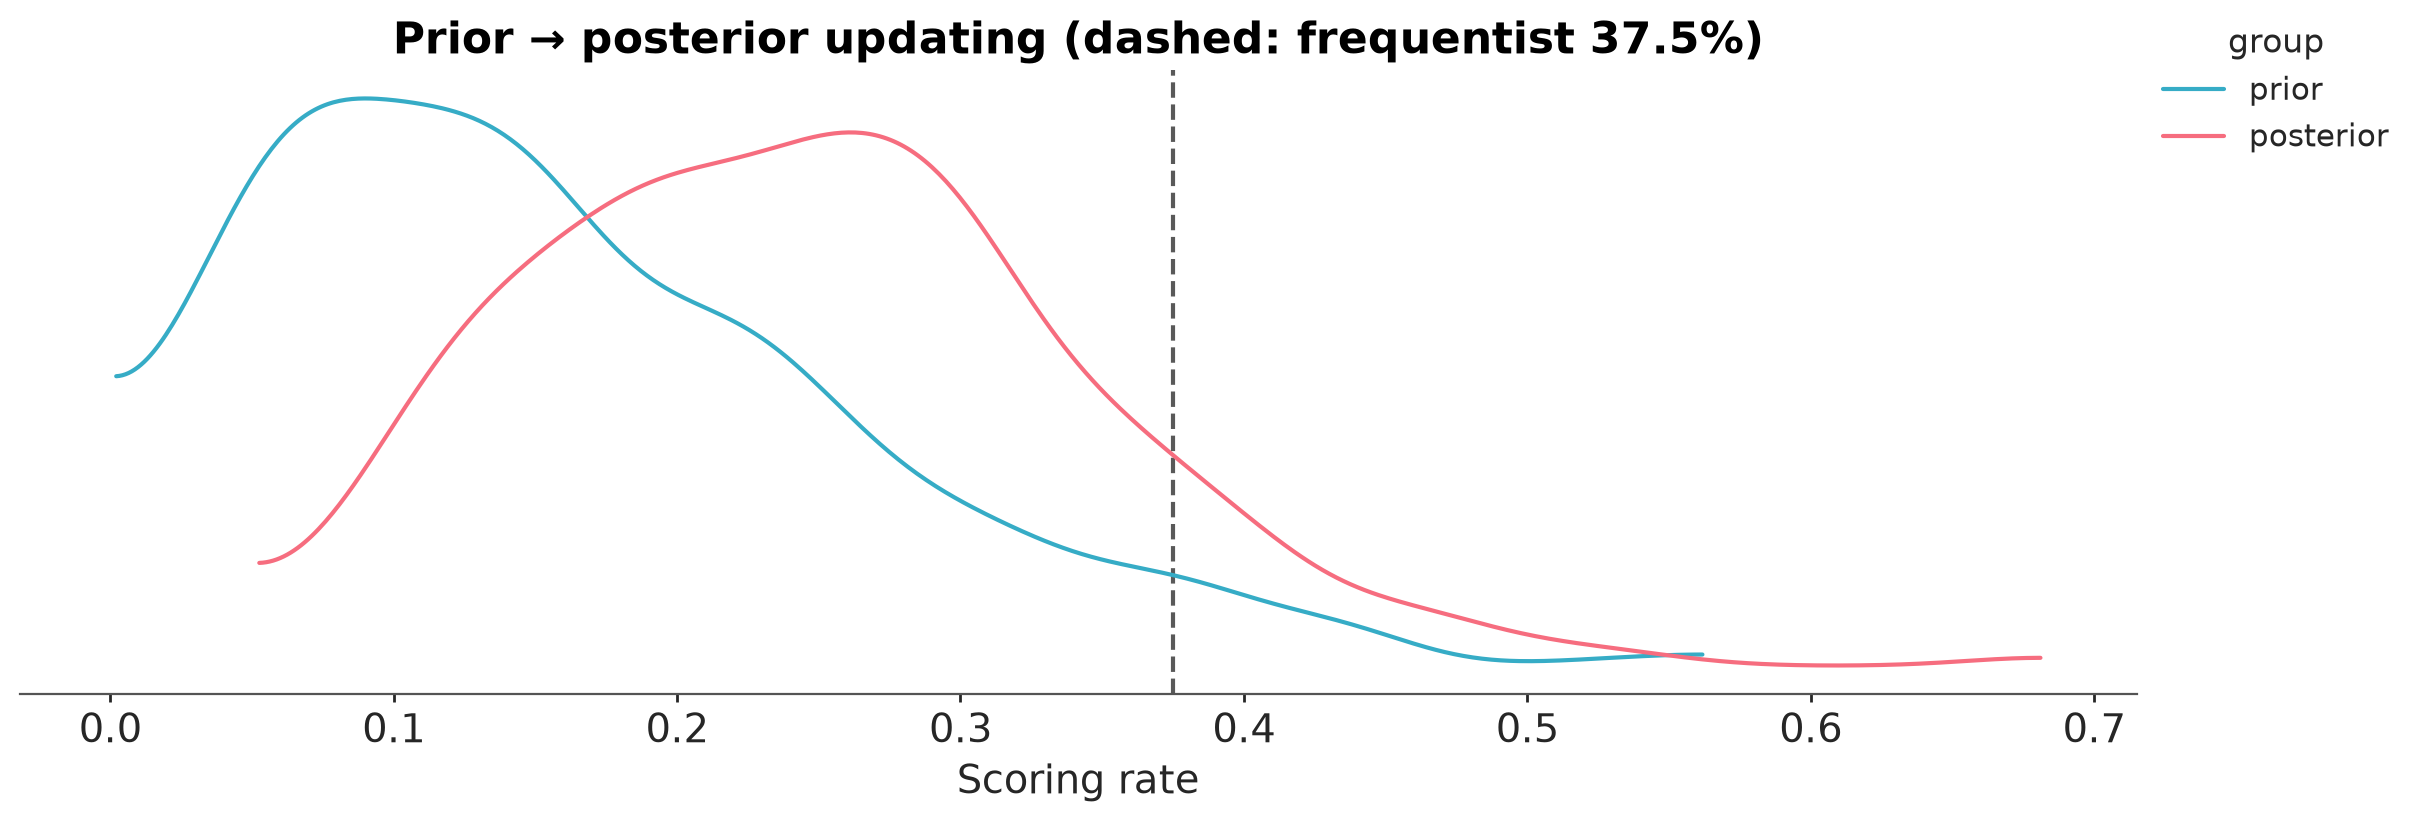

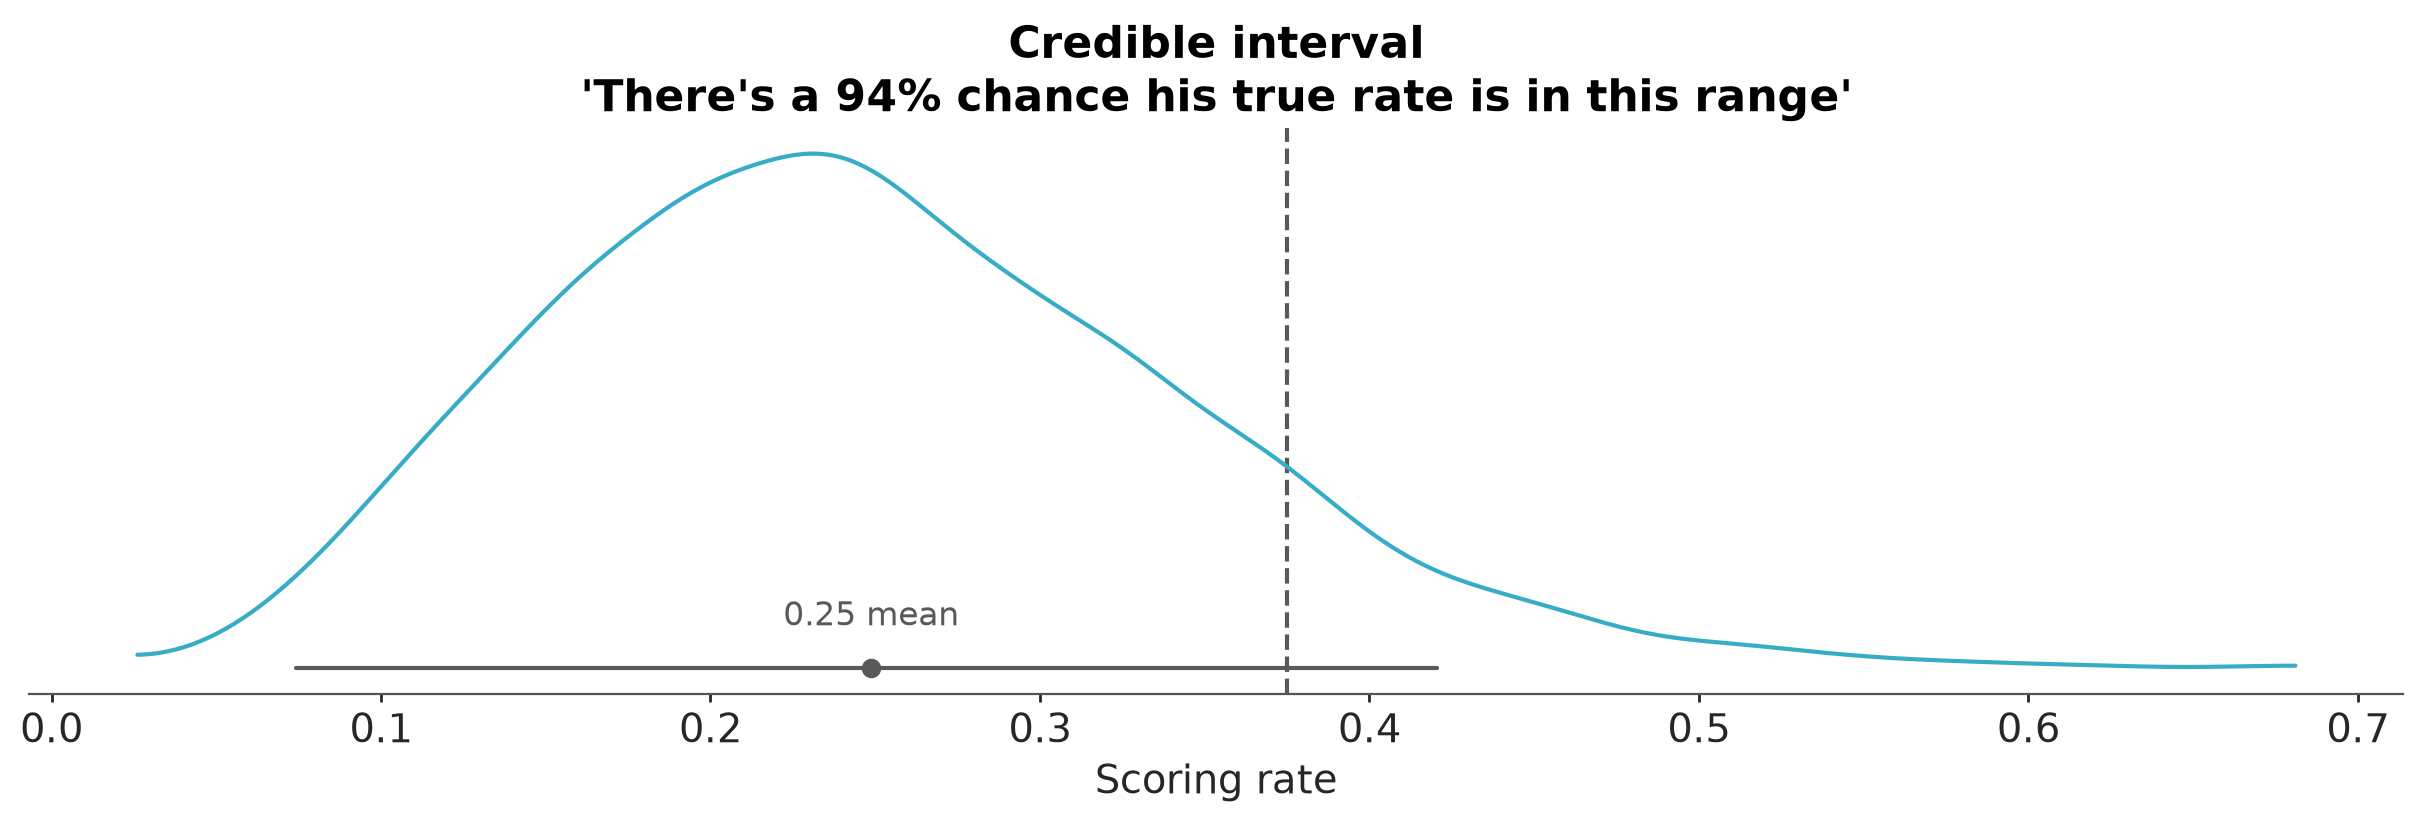

In [4]:
pc = azp.plot_prior_posterior(simple_trace, var_names="scoring_rate", figure_kwargs={"figsize": (12, 4)})
azp.add_lines(pc, n_goals / n_appearances, color="C2", linestyle="--")
pc.viz["plot"]["scoring_rate"].item().set(
    xlabel="Scoring rate", title=f"Prior → posterior updating (dashed: frequentist {n_goals / n_appearances:.1%})"
)

pc = azp.plot_dist(simple_trace, var_names="scoring_rate", figure_kwargs={"figsize": (12, 4)})
azp.add_lines(pc, n_goals / n_appearances, color="C2", linestyle="--")
pc.viz["plot"]["scoring_rate"].item().set(
    xlabel="Scoring rate", title="Credible interval\n'There's a 94% chance his true rate is in this range'"
);

### Discussion

> **Notice how the posterior is pulled away from the raw 37.5% toward our prior expectation.**
> With only 8 appearances, we're not very certain: the credible interval is wide.
> As the player makes more appearances, the data will dominate and the interval will shrink.
>
> This is *exactly* what you want for transfer decisions: **"We think he scores around 25% of the time, anywhere from about 7% to 42% is plausible, and here's how sure we are."**

**Question for the group:** How would this change if we had 80 appearances instead of 8?

---
# Part 2 — Your First Football Model

Now let's scale this up. Instead of one player, let's model **many players simultaneously** using real match data.

This is where Bayesian modeling really shines: **hierarchical models** let us share information across players while still estimating individual abilities.

## Load the Data

We'll use match-level data from the four big leagues (Premier League, La Liga, Bundesliga and Serie A), from 2000/01 to 2023/24.
Each row is one player in one match: did they score (at least once) or not, along with team/opponent context.

In [5]:
DATA_URL = "https://raw.githubusercontent.com/AlexAndorra/cmsac-2026/main/data/"
if Path("data/player_matches.csv").exists():  # running from a clone of the repo
    DATA_URL = "data/"

full_data = pd.read_csv(DATA_URL + "player_matches.csv")
full_data["player"] = full_data["name_player"].str.replace("-", " ").str.title()

print(
    f"Dataset: {len(full_data):,} player-match records, {full_data.player.nunique()} players, {full_data.season.nunique()} seasons, {full_data.name_league.nunique()} leagues"
)
full_data

Dataset: 33,678 player-match records, 144 players, 24 seasons, 4 leagues


,name_player,name_team,name_opp,name_league,season,season_nbr,matchday,kick_off,home_pitch,points_diff,goal_balance_diff,goals_in_match,goal,player
0,adam-szalai,1. FSV Mainz 05,Bayer 04 Leverkusen,bundesliga,2009/10,0,18,2010-01-16,0,0,0,0,0,Adam Szalai
1,adam-szalai,1. FSV Mainz 05,Hannover 96,bundesliga,2009/10,0,19,2010-01-23,1,7,6,0,0,Adam Szalai
2,adam-szalai,1. FSV Mainz 05,Bayern München,bundesliga,2009/10,0,20,2010-01-30,0,-12,-24,0,0,Adam Szalai
3,adam-szalai,1. FSV Mainz 05,Bor. Mönchengladbach,bundesliga,2009/10,0,21,2010-02-07,1,2,0,0,0,Adam Szalai
4,adam-szalai,1. FSV Mainz 05,Hertha BSC,bundesliga,2009/10,0,22,2010-02-13,0,19,20,0,0,Adam Szalai
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33673,zlatan-ibrahimovic,AC Mailand,Sassuolo Calcio,serie-a,2021/22,12,38,2022-05-22,0,33,34,0,0,Zlatan Ibrahimovic
33674,zlatan-ibrahimovic,AC Mailand,Atalanta Bergamo,serie-a,2022/23,13,24,2023-02-26,1,0,0,0,0,Zlatan Ibrahimovic
33675,zlatan-ibrahimovic,AC Mailand,AC Florenz,serie-a,2022/23,13,25,2023-03-04,0,19,14,0,0,Zlatan Ibrahimovic
33676,zlatan-ibrahimovic,AC Mailand,US Salernitana,serie-a,2022/23,13,26,2023-03-13,1,22,26,0,0,Zlatan Ibrahimovic


In [6]:
# Let's work with a curated subset of well-known players for speed
players_ordered = sorted(
    [
        # Legends & superstars
        "cristiano-ronaldo",
        "lionel-messi",
        "robert-lewandowski",
        "erling-haaland",
        "harry-kane",
        "mohamed-salah",
        # Top strikers
        "karim-benzema",
        "luis-suarez",
        "sergio-aguero",
        "zlatan-ibrahimovic",
        "thierry-henry",
        "antoine-griezmann",
        "mario-gomez",
        "stefan-kiessling",
        "ailton",
        "luca-toni",
        # Interesting cases
        "luis-fabiano",
        "peter-crouch",
        "hugo-almeida",
        "nani",
        "andre-silva",
        "joao-felix",
        # More variety
        "paulo-sergio",
        "oliver-neuville",
        "ricardo-quaresma",
        "helder-postiga",
        "arjen-robben",
    ]
)

complete_data = (
    full_data[full_data.name_player.isin(players_ordered)].sort_values(["player", "kick_off"]).reset_index(drop=True)
)

# we keep each player's last season aside, to check later how the models predict matches they have never seen
is_last_season = complete_data["season"] == complete_data.groupby("player")["season"].transform("max")
train_data = complete_data[~is_last_season].reset_index(drop=True)
test_data = complete_data[is_last_season].reset_index(drop=True)

print(
    f"Working with {complete_data.player.nunique()} players: {len(train_data):,} matches to train on, {len(test_data):,} kept aside (each player's last season)"
)

Working with 27 players: 6,996 matches to train on, 530 kept aside (each player's last season)


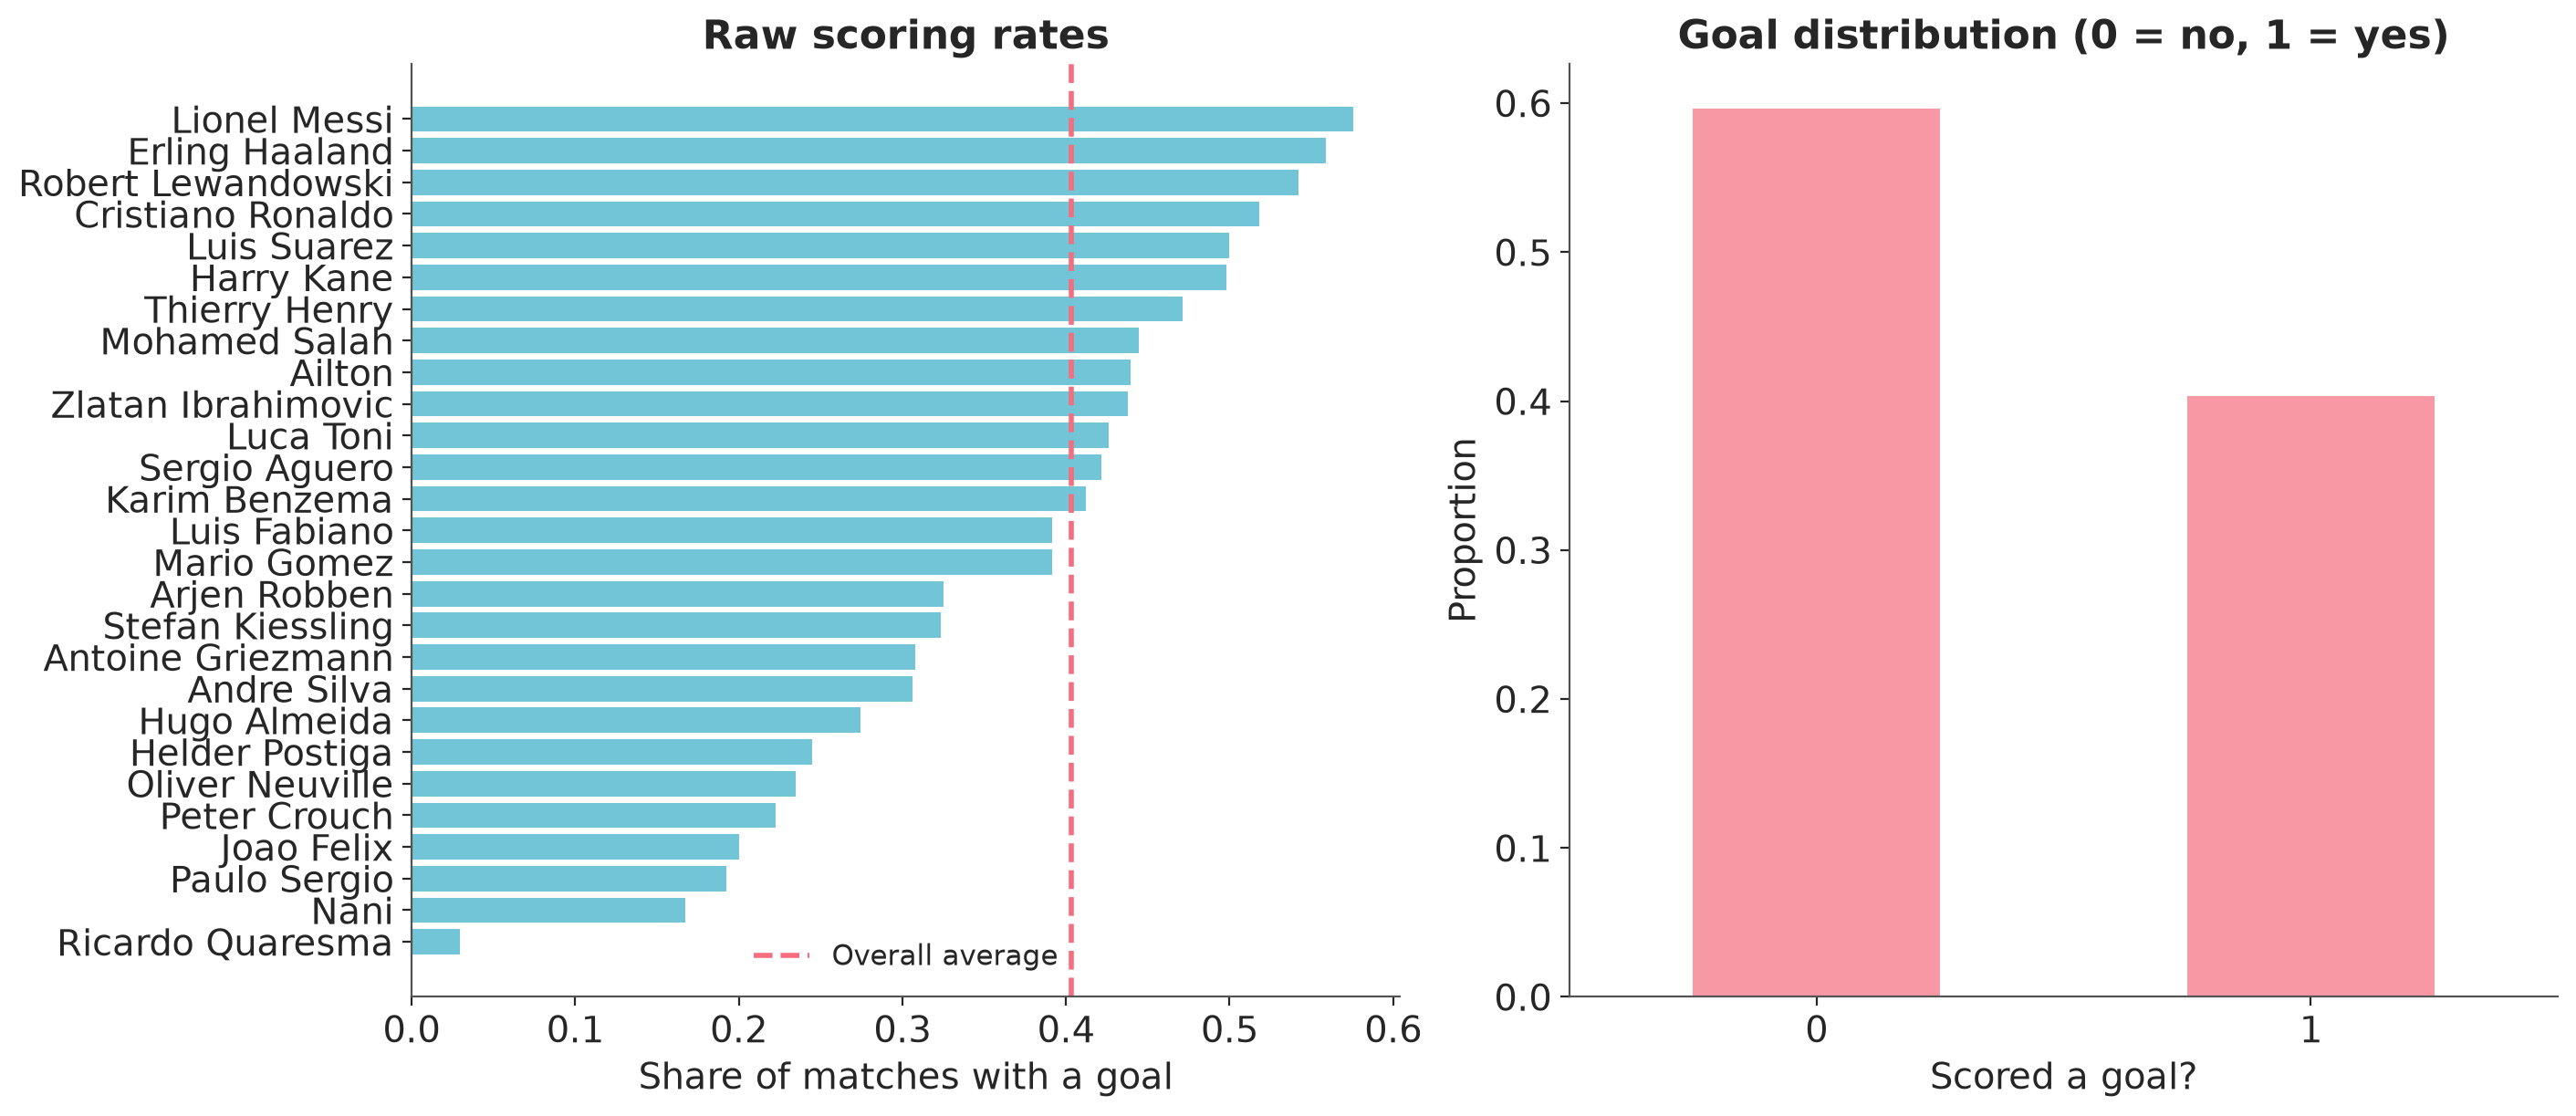

In [7]:
# Quick look at the scoring landscape
player_stats = (
    train_data.groupby("player")
    .agg(games=("goal", "size"), goals=("goal", "sum"))
    .assign(scoring_rate=lambda df: df.goals / df.games)
    .sort_values("scoring_rate")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

axes[0].barh(player_stats.index, player_stats.scoring_rate, alpha=0.7)
axes[0].axvline(train_data.goal.mean(), color="C1", ls="--", lw=2, label="Overall average")
axes[0].set(xlabel="Share of matches with a goal", title="Raw scoring rates")
axes[0].legend()

train_data["goal"].value_counts(normalize=True).sort_index().plot.bar(ax=axes[1], alpha=0.7, rot=0, color="C1")
axes[1].set(xlabel="Scored a goal?", ylabel="Proportion", title="Goal distribution (0 = no, 1 = yes)");

### Discussion

> **These raw rates are what clubs usually look at.** But they don't account for:
> - Playing for a dominant vs. weaker team
> - Home vs. away effects
> - Opponent strength
> - How many games they've played (sample size!)
>
> **Question for the group:** Which of these raw rates do you trust the most? The least? Why?

## The Hierarchical Model

Here's the key idea: instead of estimating each player independently, we let the model **learn how much variation exists across players** and use that to regularize individual estimates.

Players with fewer games get pulled toward the group average (more regularization).
Players with many games get estimates close to their raw data (less regularization).

This is called **partial pooling**, the sweet spot between:
- *No pooling*: treat every player independently (noisy for small samples)
- *Complete pooling*: assume all players are the same (ignores individual differences)

In [8]:
# Encode player IDs for the model
player_idx, players = pd.factorize(train_data["player"], sort=True)

coords_simple = {"player": players, "obs_id": train_data.index}

### Choosing Priors with Domain Knowledge

Before writing the model, let's think about what we know:
- These are some of the best forwards of the last 25 years: a typical one scores in somewhere between 15% and 50% of his matches (more than the new signing above!)
- There's real variation between players, but not *that* much: nobody scores in 95% of his matches

We use [preliz](https://preliz.readthedocs.io/en/latest/) to translate this domain knowledge into proper prior distributions:

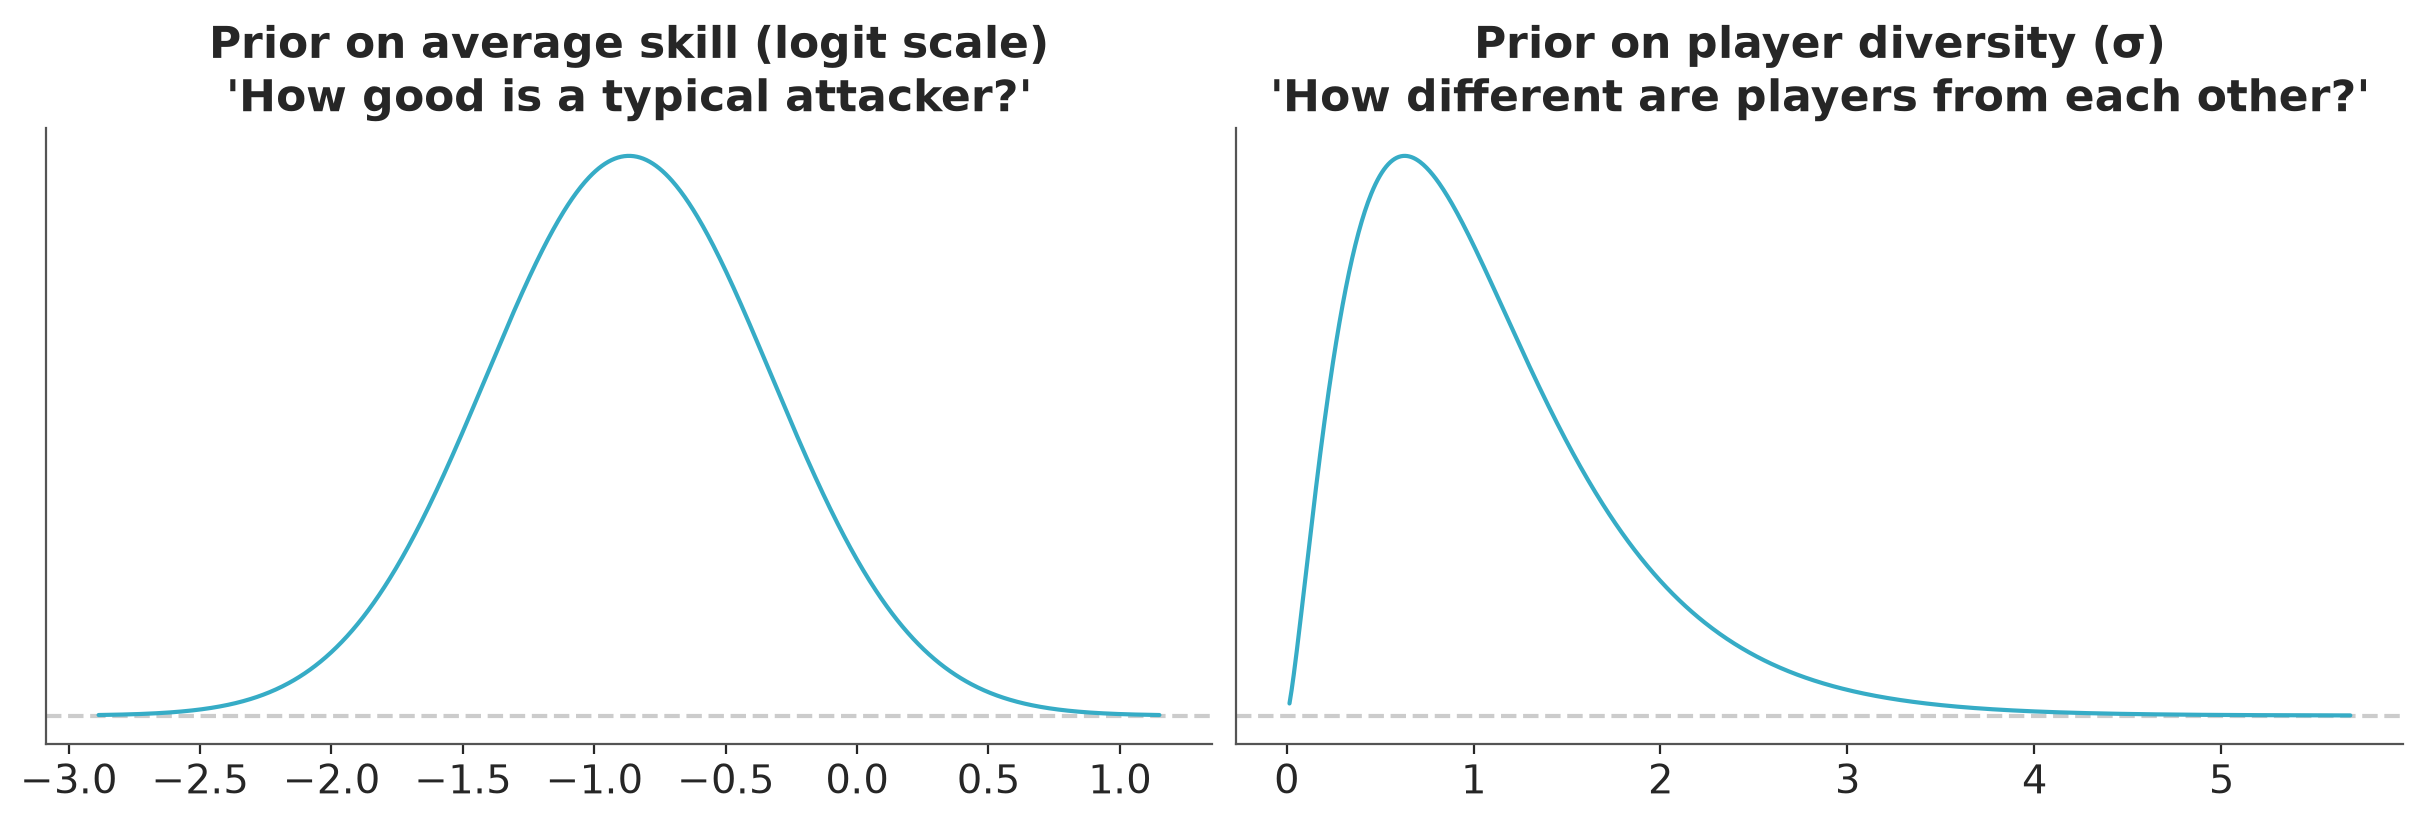

In [9]:
# average skill across players (logit scale): a typical attacker scores in 15% to 50% of his matches
average_skill_dist = pz.maxent(pz.Normal(), logit(0.15), logit(0.5), plot=False)
# how much variation across players? (logit scale)
player_diversity_dist = pz.maxent(pz.Gamma(), 0.1, 2, plot=False)

_, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

average_skill_dist.plot_pdf(ax=axes[0], legend=False)
axes[0].set(title="Prior on average skill (logit scale)\n'How good is a typical attacker?'")

player_diversity_dist.plot_pdf(ax=axes[1], legend=False)
axes[1].set(title="Prior on player diversity (σ)\n'How different are players from each other?'");

### Discussion

> `preliz.maxent` finds the **maximum entropy** distribution that satisfies our constraints.
> Translation: "the least opinionated distribution that's still consistent with what we know."
>
> We're saying: *"player diversity is probably between 0.1 and 2 on the logit scale."*
> That's a pretty gentle constraint: we're letting the data do most of the talking.

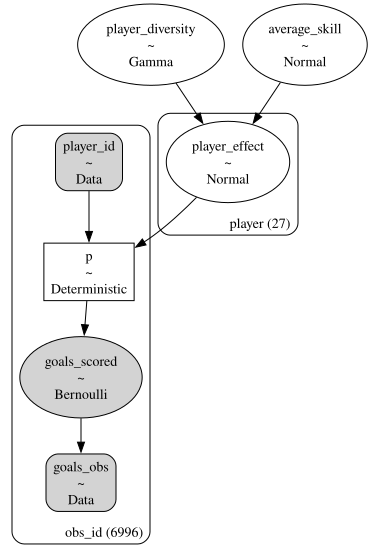

In [10]:
with pm.Model(coords=coords_simple) as hierarchical_model:
    # --- Data ---
    player_id_data = pm.Data("player_id", player_idx, dims="obs_id")
    goals_obs = pm.Data("goals_obs", train_data["goal"].to_numpy(), dims="obs_id")

    # --- Priors ---
    # Average skill across players, and how different players are from each other (see the prior plots above)
    average_skill = average_skill_dist.to_pymc("average_skill")
    sigma = player_diversity_dist.to_pymc("player_diversity")

    # Individual player skill on logit scale, drawn around the average
    player_effect = pm.Normal("player_effect", mu=average_skill, sigma=sigma, dims="player")

    # --- Likelihood ---
    # Sigmoid maps logit-scale effects to [0, 1] probability
    p = pm.Deterministic("p", pm.math.sigmoid(player_effect[player_id_data]), dims="obs_id")
    # Each appearance is a Bernoulli trial: goal or no goal
    pm.Bernoulli("goals_scored", p=p, observed=goals_obs, dims="obs_id")

pm.model_to_graphviz(hierarchical_model)

### Discussion

> **What this graph is telling us:**
> - `average_skill` is where the population of players is centered
> - `player_diversity` controls how spread out the players are from each other
> - Each `player_effect` is drawn from a shared Normal distribution
> - The sigmoid function maps logit-scale effects to goal probabilities
> - Each observation is a Bernoulli trial (goal or no goal)
>
> **This is the "partial pooling" in action.** The model learns `player_diversity` from data:
> if players are truly different, `player_diversity` will be large; if they're similar, `player_diversity` will be small.

### Prior Predictive Check: Does Our Model Make Sense Before Seeing Data?

In [11]:
with hierarchical_model:
    prior = pm.sample_prior_predictive(draws=500, random_seed=rng)

Sampling: [average_skill, goals_scored, player_diversity, player_effect]


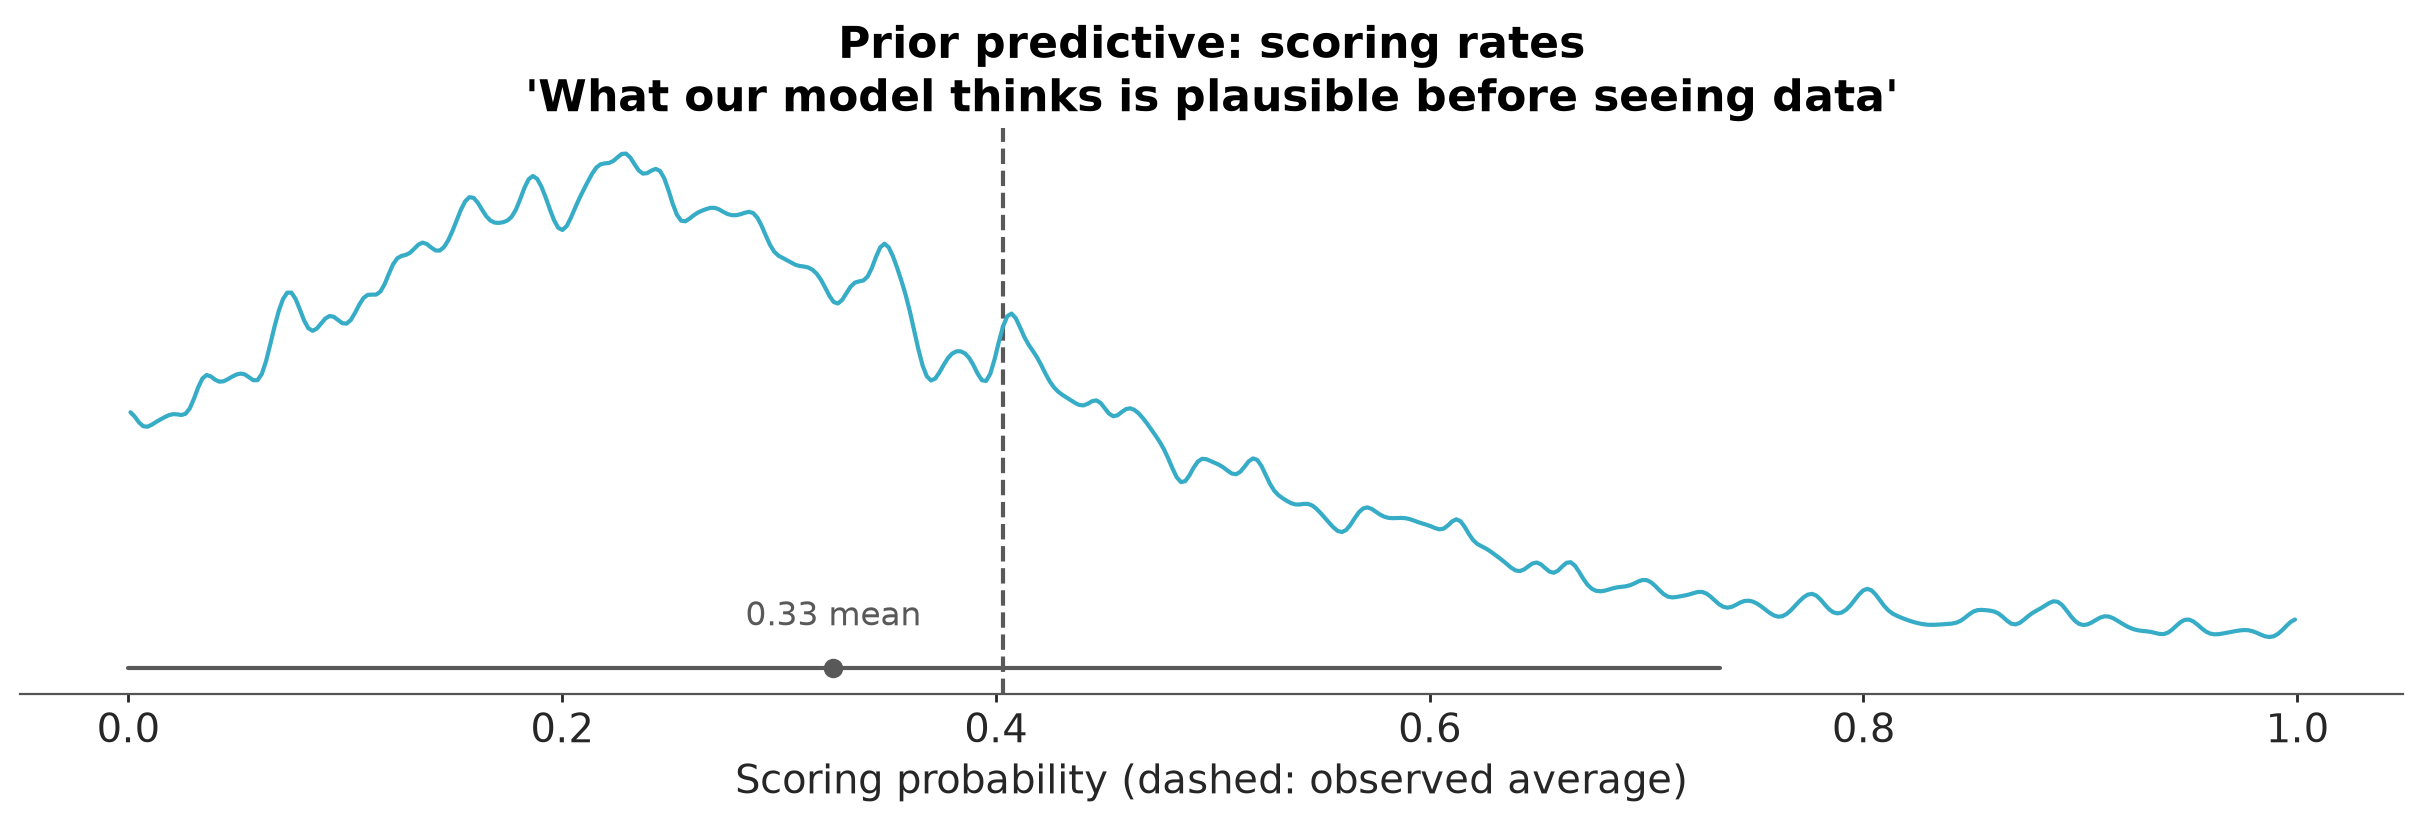

In [12]:
pc = azp.plot_dist(
    prior, group="prior", var_names="p", sample_dims=["chain", "draw", "obs_id"], figure_kwargs={"figsize": (12, 4)}
)
azp.add_lines(pc, train_data["goal"].mean(), color="C1", linestyle="--")
pc.viz["plot"]["p"].item().set(
    xlabel="Scoring probability (dashed: observed average)",
    title="Prior predictive: scoring rates\n'What our model thinks is plausible before seeing data'",
);

### Discussion

> **Prior predictive checks are your safety net.** Before burning compute on sampling,
> verify that your priors produce plausible data.
>
> If the prior predictive shows scoring rates of 90%, something's wrong with your priors!
>
> **Question for the group:** Does this distribution of scoring rates look reasonable for professional strikers?

### Sample the Model

In [13]:
with hierarchical_model:
    idata_simple = pm.sample(**sampler_kwargs())
    idata_simple.update(prior)
    pm.sample_posterior_predictive(idata_simple, extend_inferencedata=True, random_seed=rng)
    pm.compute_log_likelihood(idata_simple, extend_inferencedata=True)

NUTS[nutpie]: [average_skill, player_diversity, player_effect]


Output()

Sampling: [goals_scored]


Output()

Output()

In [14]:
# First-pass convergence check: R-hat, ESS, divergences, tree depth, E-BFMI
azs.diagnose(idata_simple);

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


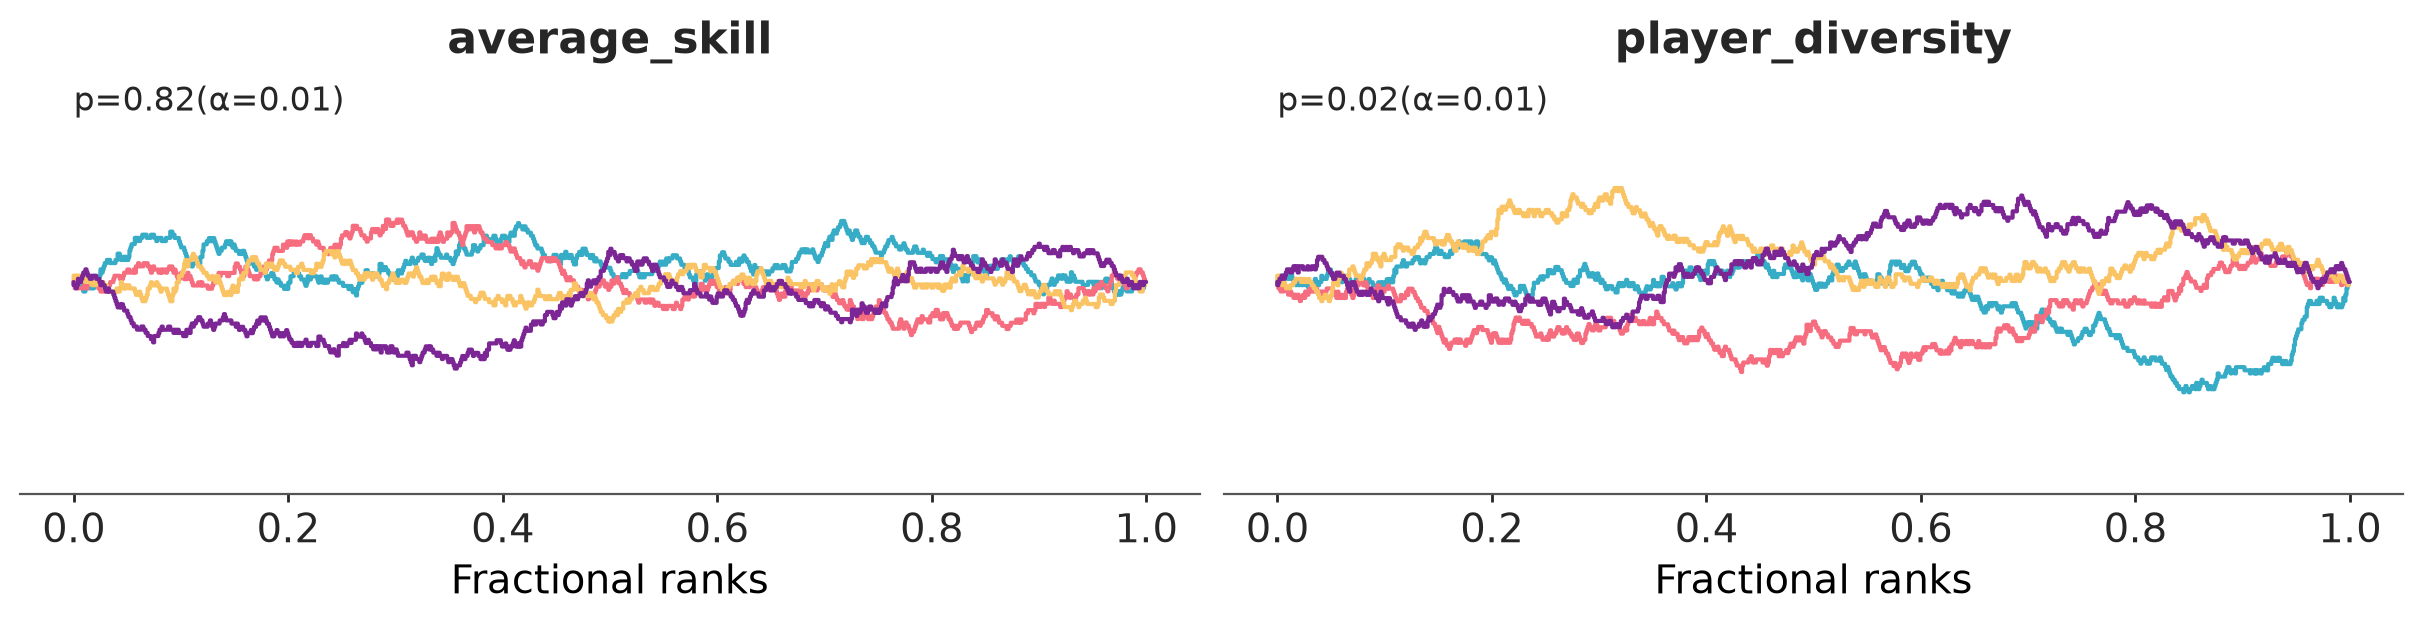

In [15]:
azp.plot_rank(idata_simple, var_names=["average_skill", "player_diversity"], figure_kwargs={"figsize": (12, 3)});

### Discussion

> **What to look for in diagnostics:**
> - `r_hat` close to 1.0 (chains agree with each other)
> - `ess_bulk` and `ess_tail` > 100 * number of chains (enough effective samples)
> - No divergences (the sampler explored the posterior without issues)
> - Rank plots: the chains' lines should overlap, all wandering around the same level; the p-value tests exactly that, and a tiny one (below α) flags chains that disagree
>
> These are like unit tests for your Bayesian model: always run them.

### Results: Who's Actually Good?

In [16]:
# Convert player effects to scoring probabilities
scoring_probs = expit(idata_simple.posterior["player_effect"]).rename("scoring_prob")
results = azs.summary(scoring_probs.to_dataset(), kind="stats", round_to=3)
results.index = scoring_probs.player.to_numpy()  # one row per player, in the same order
results = results.join(player_stats[["scoring_rate", "games"]]).sort_values("mean", ascending=False)
results

,mean,sd,hdi94_lb,hdi94_ub,scoring_rate,games
Lionel Messi,0.570,0.023,0.527,0.611,0.575556,450
Erling Haaland,0.537,0.049,0.447,0.627,0.559140,93
Robert Lewandowski,0.536,0.025,0.491,0.583,0.542105,380
Cristiano Ronaldo,0.515,0.021,0.477,0.553,0.518261,575
Luis Suarez,0.495,0.028,0.440,0.544,0.500000,312
Harry Kane,0.493,0.029,0.443,0.550,0.498282,291
Thierry Henry,0.466,0.030,0.409,0.522,0.471042,259
Mohamed Salah,0.441,0.029,0.392,0.501,0.444444,288
Zlatan Ibrahimovic,0.436,0.027,0.381,0.484,0.438095,315
Ailton,0.434,0.039,0.361,0.505,0.439490,157


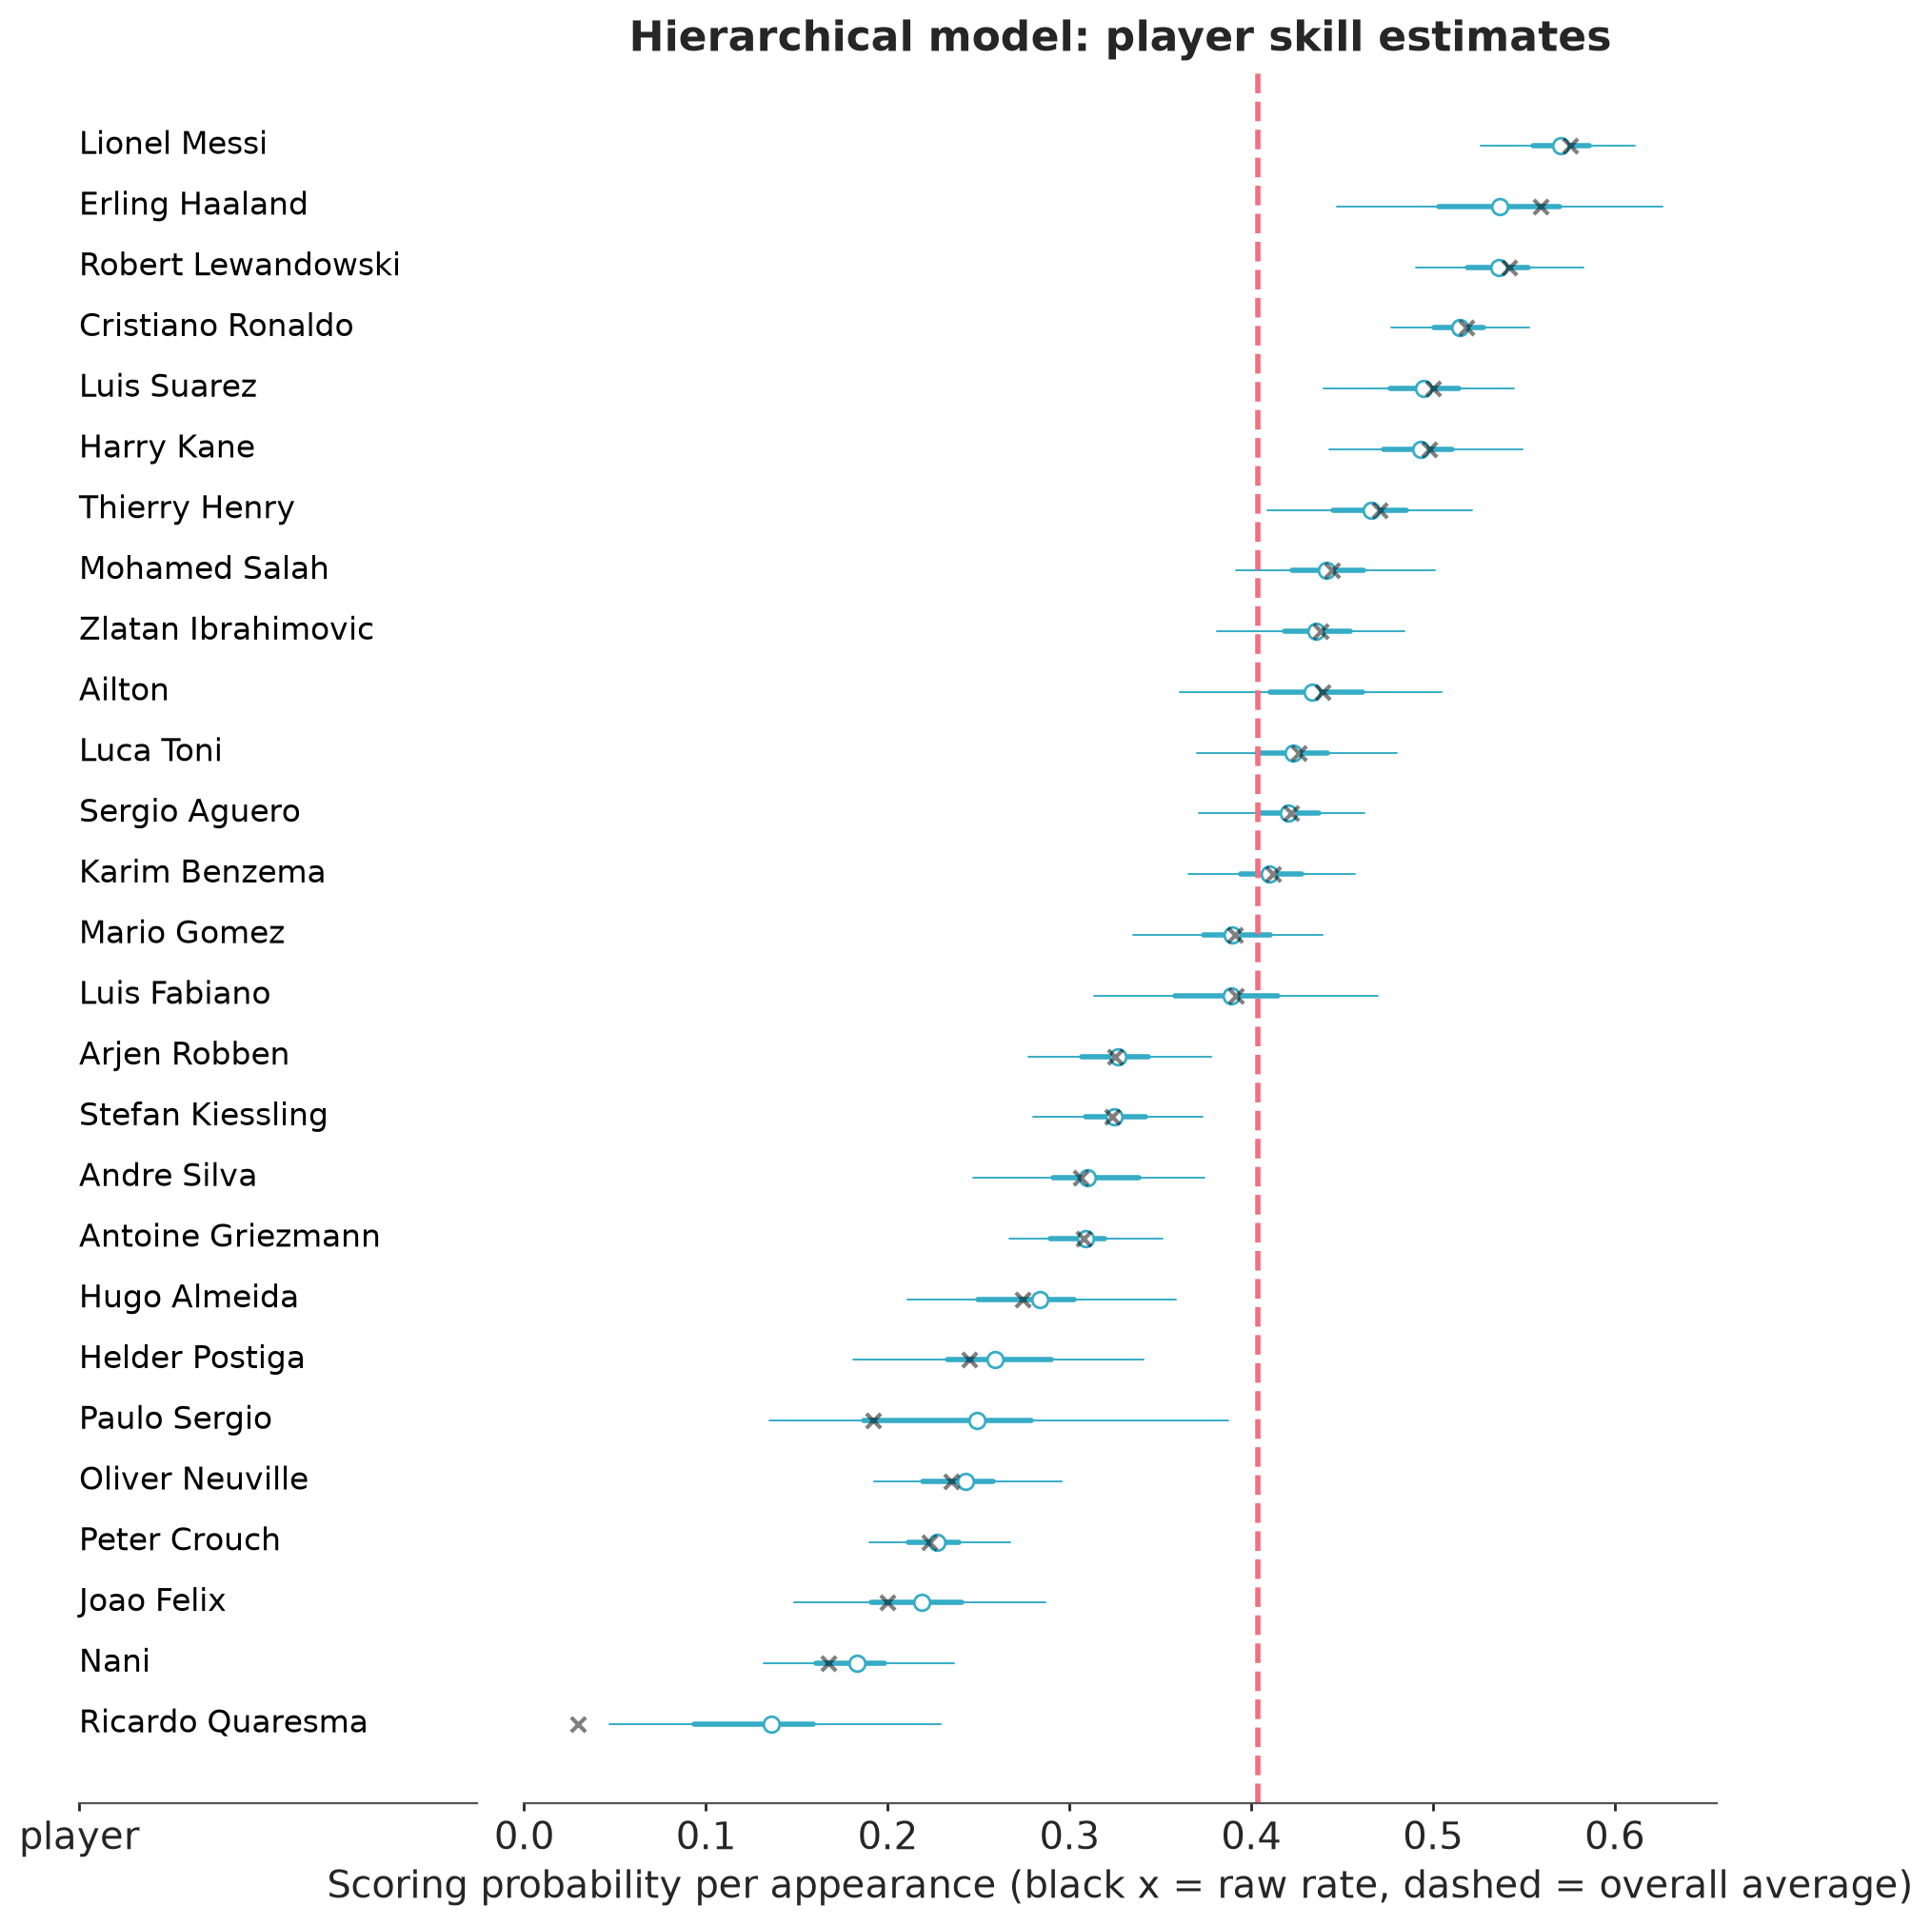

In [17]:
by_skill = results.index  # best first
raw_rates = results["scoring_rate"].rename_axis("player").to_xarray().rename("scoring_prob")

pc = azp.plot_forest(scoring_probs.sel(player=by_skill).to_dataset(), combined=True, labels=["player"])
pc.map(
    azp.visuals.scatter_x,
    "raw rate",
    data=raw_rates.sel(player=by_skill).to_dataset(),
    coords={"column": "forest"},
    marker="x",
    color="k",
    alpha=0.5,
    size=30,
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(train_data.goal.mean(), color="C1", ls="--", lw=2)
ax.set(
    xlabel="Scoring probability per appearance (black x = raw rate, dashed = overall average)",
    title="Hierarchical model: player skill estimates",
)
pc.viz["figure"].item().set_size_inches(9, 10)

### Discussion

> **Key things to notice:**
> 1. **Shrinkage**: Players with fewer games get pulled more toward the average (wider intervals, closer to center)
> 2. **Uncertainty varies**: Lewandowski's interval is tighter than Paulo Sergio's: more data = more certainty
> 3. **Raw rate ≠ model estimate**: The black x's (raw rates) can sit away from the intervals' center: that's the model correcting for sample size
>
> **This is already more useful than raw stats.** But we're still missing something big...

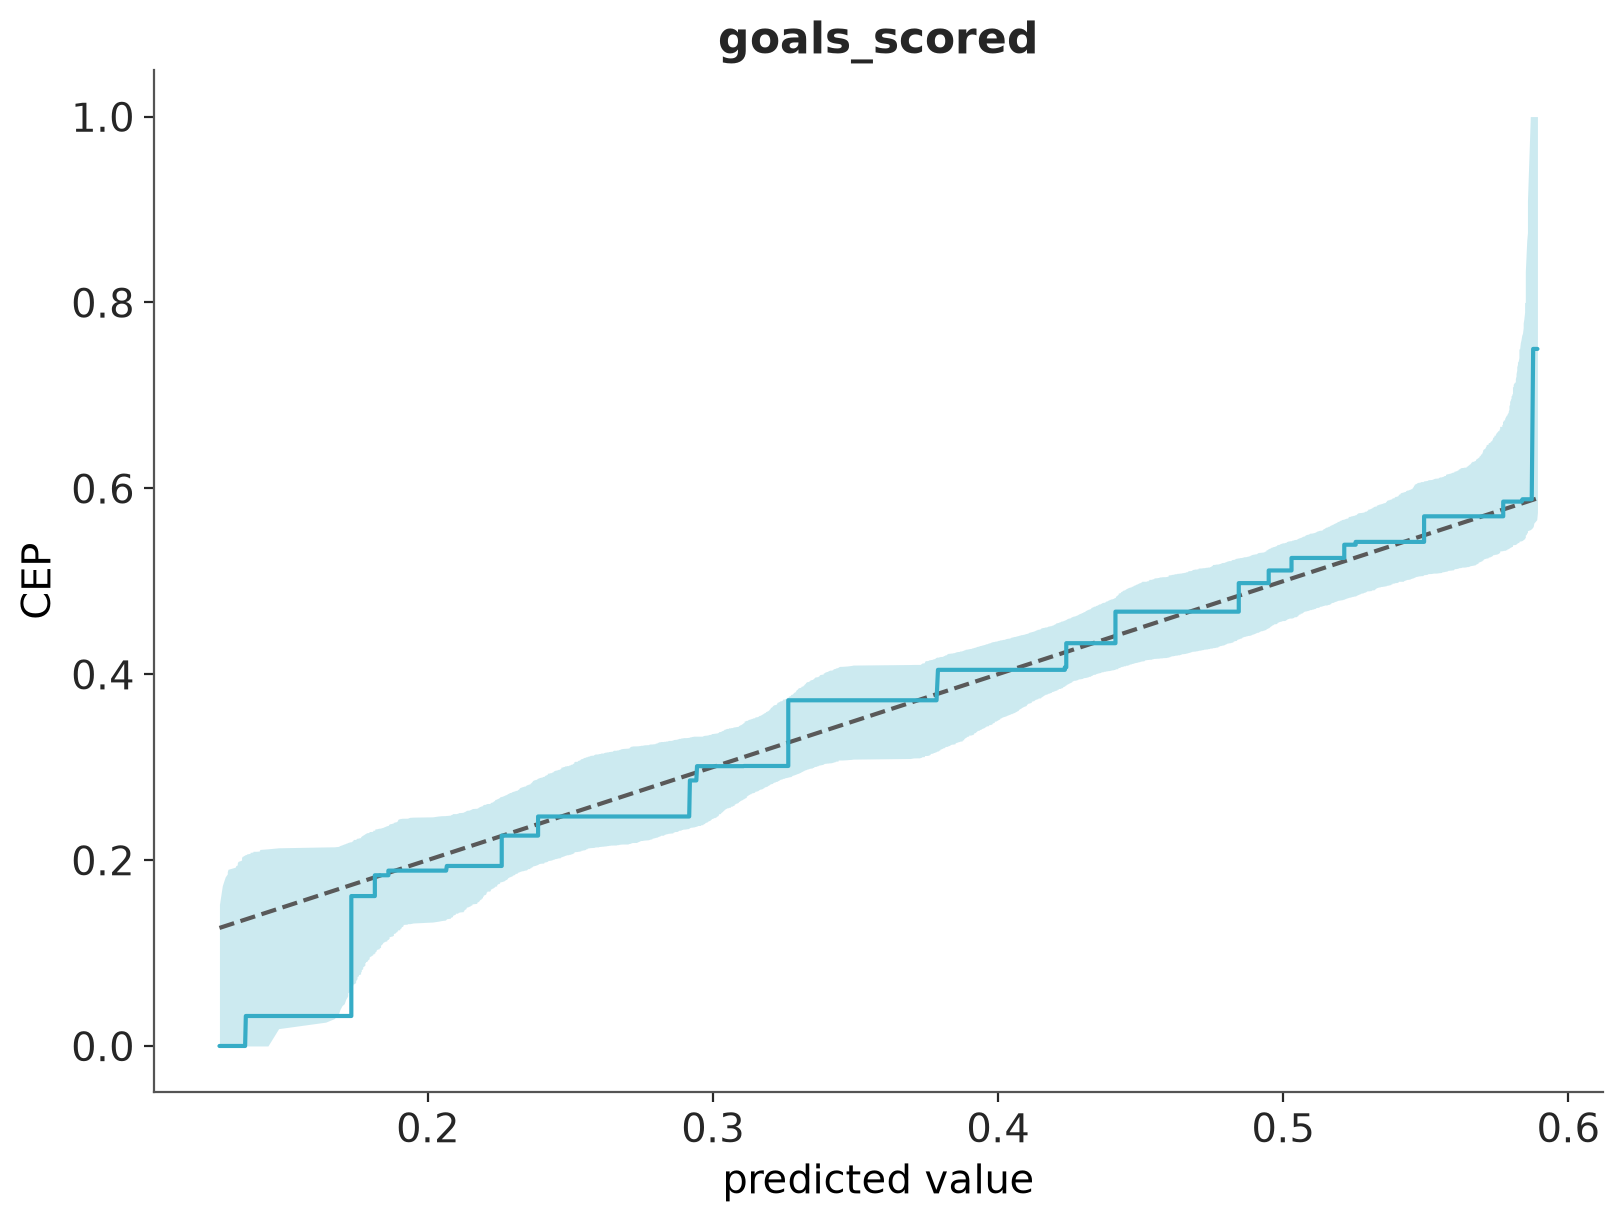

In [18]:
# Posterior predictive check: does our model generate realistic data?
azp.plot_ppc_pava(idata_simple, figure_kwargs={"figsize": (8, 6)});

The ideal calibration plot is a diagonal line, where the predicted probabilities are equal to the observed frequencies. If the line is **above the diagonal, the model is underestimating the probabilities**, and if the line is **below the diagonal, the model is overestimating the probabilities**.

The y-axis is labeled as CEP, short for "conditional event probabilities". A CEP represents the probability that an event occurs, given that the classifier assigned a particular predicted probability.

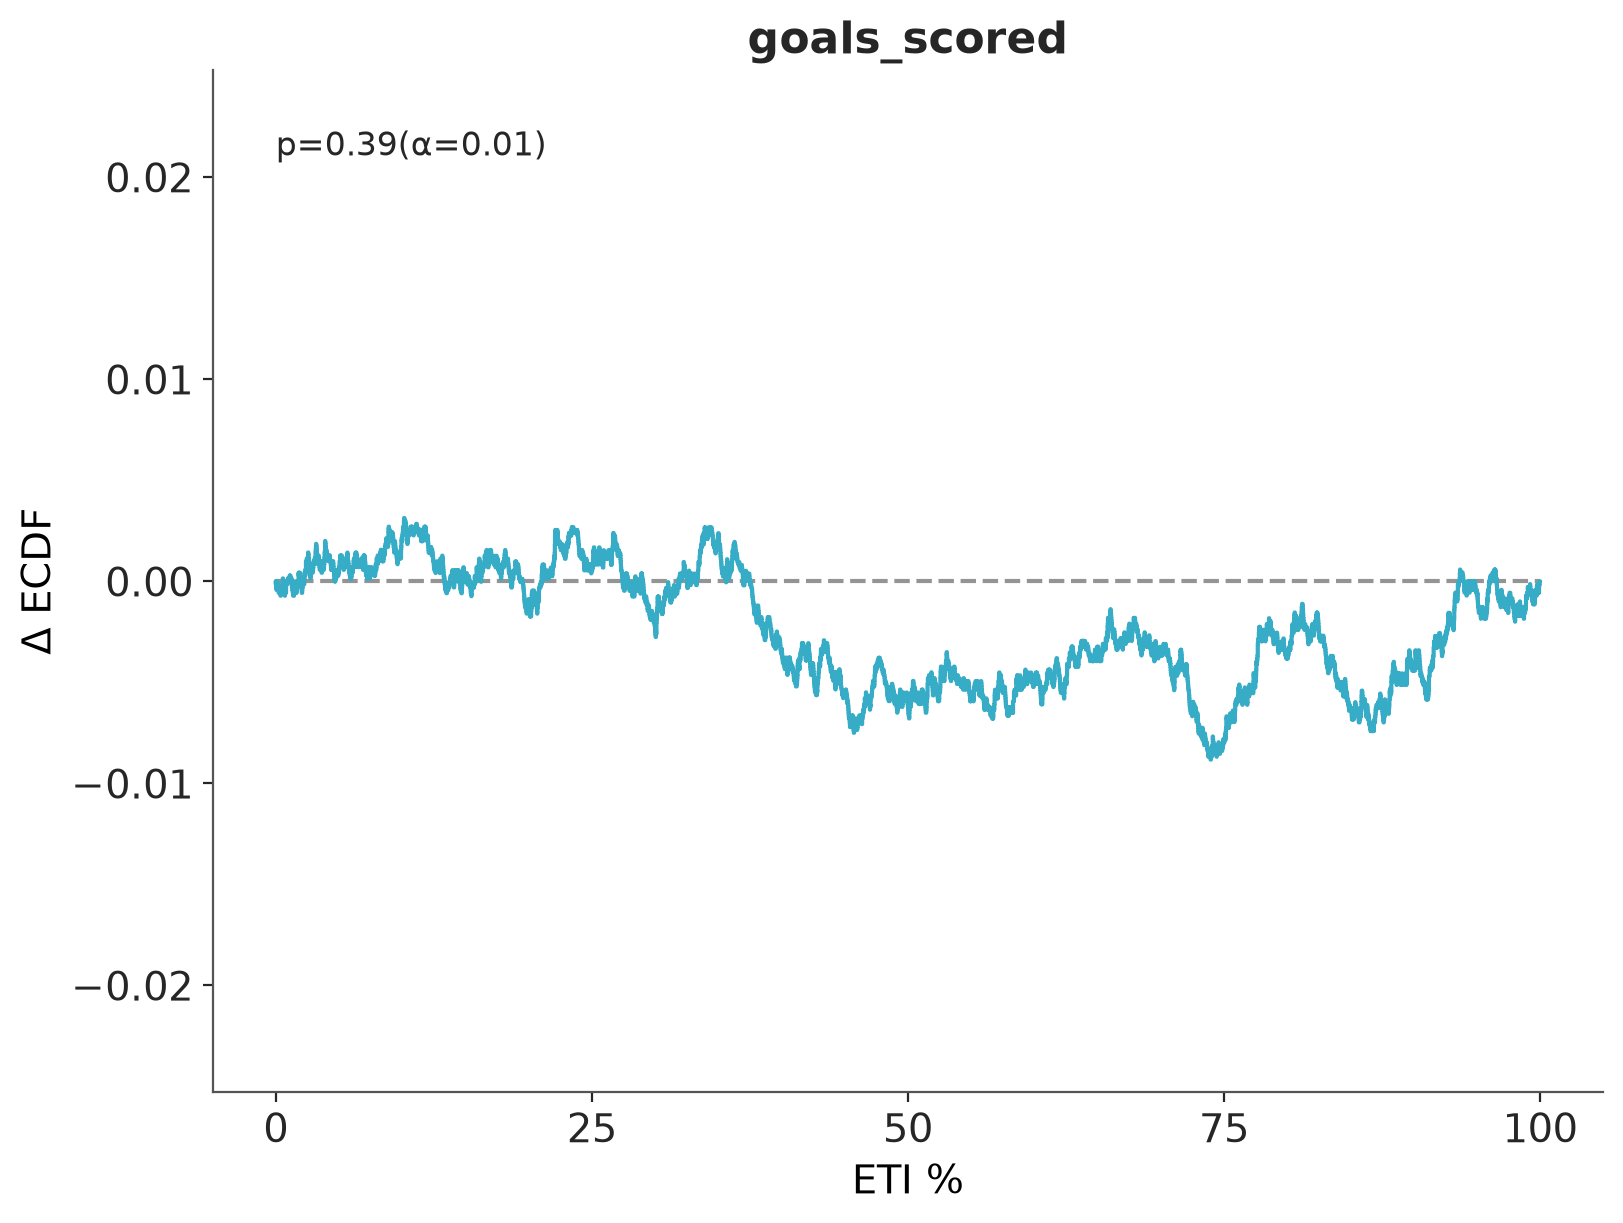

In [19]:
# LOO-PIT calibration check
azp.plot_loo_pit(idata_simple, coverage=True, figure_kwargs={"figsize": (8, 6)});

### Discussion

> **LOO-PIT coverage is your calibration check**, out of sample: it leaves each match out in turn and asks **"when the model says X%, is it right X% of the time?"**, for every interval width at once.
>
> The x-axis is the interval the model claims (50%, 80%, 90%…); the y-axis is how far its *actual* coverage falls above or below that claim. **A model that keeps its promises sits on the flat dashed line at zero; below zero is over-confident (predictions too narrow); above zero is cautious (predictions too wide).**
>
> The p-value is one global **test that the model is calibrated** (α = 0.01 by default). Red points only show up when that test fails: they are the matches that break calibration the most.
>
> This is the Bayesian equivalent of checking "when I say 90% confident, am I right 90% of the time?"

---
# Part 3 — When Form Changes: Gaussian Processes

Our model so far assumes each player has a **single, fixed** scoring ability.
But we all know that's not true:

- Players have **hot and cold streaks** within a season
- They **peak and decline** across their career
- Injuries, transfers, and tactical changes all affect form

We need a model that lets ability **evolve smoothly over time**.
Enter: **[Gaussian Processes](https://alexandorra.github.io/pollsposition_blog/popularity/macron/gaussian%20processes/polls/2021/01/18/gp-popularity.html)**!

## GP Intuition: Functions with Uncertainty

A Gaussian Process is a **distribution over functions**. Instead of fitting a fixed curve (like a polynomial), a GP says:

> *"I don't know the exact function, but I know it should be **smooth**
> and nearby points should have **correlated** values."*

This is perfect for scoring over time: we expect it to change smoothly, not jump wildly from game to game.

A GP is fully defined by:
- A **mean function** (usually zero)
- A **covariance/kernel function** that encodes smoothness

See [this tutorial](https://www.pymc.io/projects/examples/en/latest/gaussian_processes/GP-MeansAndCovs.html) for more about covariance kernels.

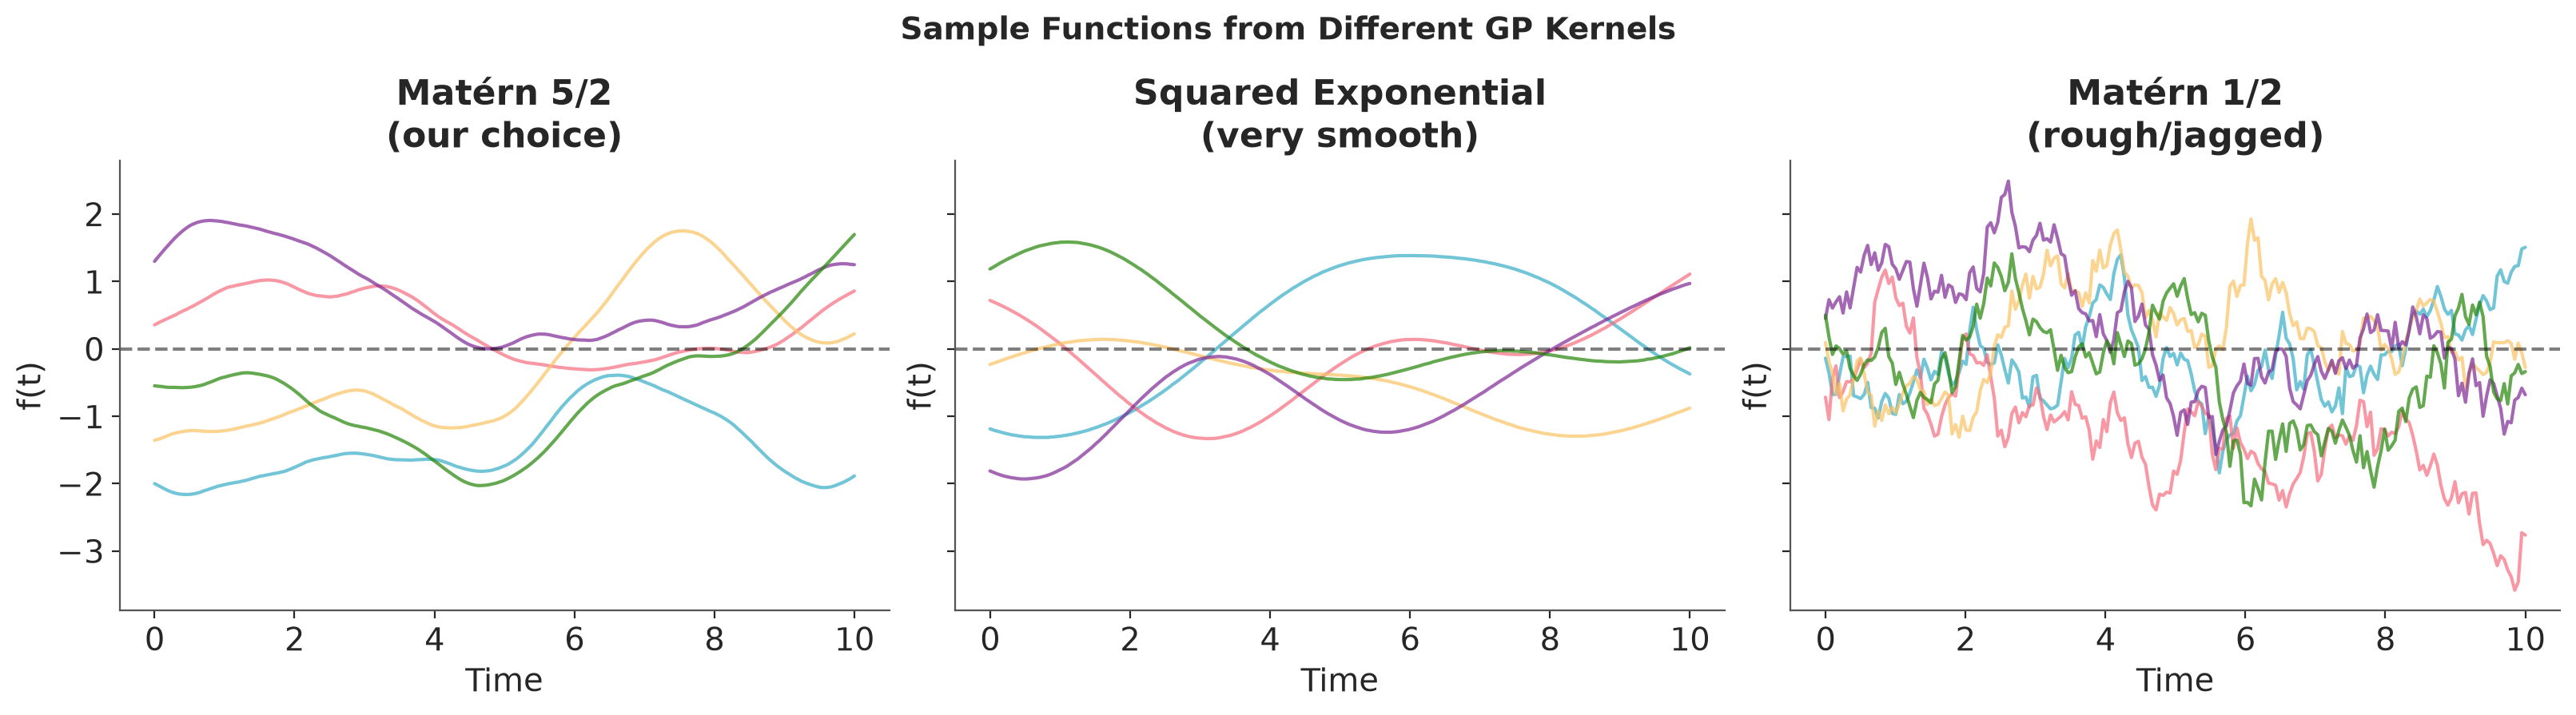

In [20]:
# Let's see what different kernels look like
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True, sharex=True, sharey=True)

X_demo = np.linspace(0, 10, 200)[:, None]

kernels = [
    ("Matérn 5/2\n(our choice)", pm.gp.cov.Matern52(1, ls=2)),
    ("Squared Exponential\n(very smooth)", pm.gp.cov.ExpQuad(1, ls=2)),
    ("Matérn 1/2\n(rough/jagged)", pm.gp.cov.Matern12(1, ls=2)),
]

for ax, (name, kernel) in zip(axes, kernels):
    K = kernel(X_demo).eval()
    # Draw sample functions
    samples = rng.multivariate_normal(np.zeros(len(X_demo)), K + 1e-6 * np.eye(len(X_demo)), size=5)
    for s in samples:
        ax.plot(X_demo.ravel(), s, alpha=0.7)
    ax.axhline(0, color="k", ls="--", alpha=0.5)
    ax.set(title=name, xlabel="Time", ylabel="f(t)")

fig.suptitle("Sample Functions from Different GP Kernels", fontsize=14, y=1.08);

### Discussion

> **Matérn 5/2** (left) is our sweet spot: smooth enough to capture real trends,
> but flexible enough to adapt to changes. It's the default choice in most applied work.
>
> The **kernel parameters** control:
> - **Amplitude**: How much can the function deviate from zero? (how dramatic are the swings?)
> - **Length scale**: How quickly does the function change? (how long do trends last?)
>
> **Question for the group:** For within-season trends, what length scale feels right? 2 games? 10 games? A full half-season?

## HSGP: Making GPs Scale

Standard GPs are beautiful but slow: they need to invert an $N \times N$ matrix, which is $O(N^3)$. With 30,000+ observations, that's a non-starter.

**[Hilbert Space Gaussian Processes (HSGP)](https://www.pymc.io/projects/examples/en/latest/gaussian_processes/HSGP-Basic.html)** solve this by approximating the GP using a truncated basis expansion, like a Fourier series for covariance functions. The cost drops to $O(Nm)$ where $m$ is the number of basis vectors.

PyMC makes this easy: `pm.gp.HSGP` is a drop-in replacement for `pm.gp.Latent`.

## Building the Temporal Model

We'll add **two** HSGP components to capture different timescales:

1. **Within-season** (short + medium term): how scoring moves across matchdays, from one week to half a season
2. **Across seasons** (long term): career stage, i.e how scoring evolves with the number of seasons a player has spent in these leagues; often referred to as "aging curve" in the sports world

Both curves are **shared by all players**: they capture population-level patterns (how scoring moves with the calendar, and with the seasons spent in these leagues), not each player's personal form. Each player's own level still comes from his skill.

This is the same multi-scale approach used in the full [Soccer Factor Model](https://www.soccerfactormodel.com/).

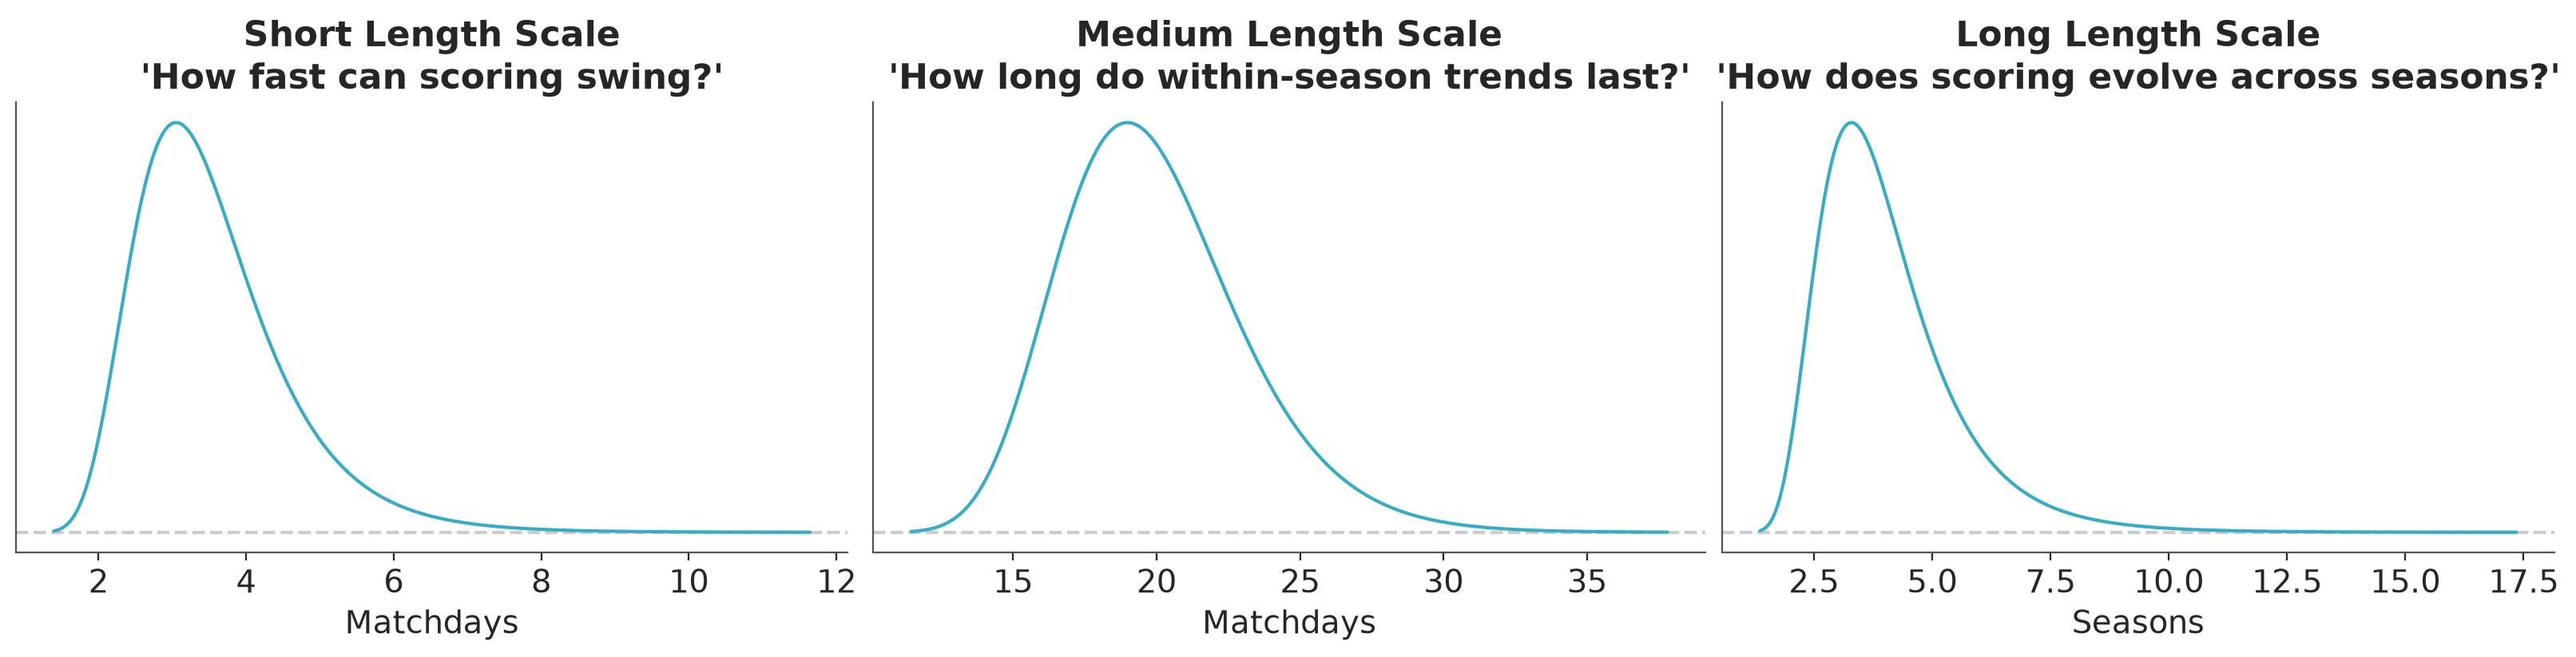

In [21]:
# Set up priors for GP length scales using domain knowledge
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)

# Short-term: 2-5 matchdays of autocorrelation (quick swings)
ls_short_dist = pz.maxent(pz.InverseGamma(), 2, 5, plot=False)
ls_short_dist.plot_pdf(ax=axes[0], legend=False)
axes[0].set(title="Short Length Scale\n'How fast can scoring swing?'", xlabel="Matchdays")

# Medium-term: 15-25 matchdays (half-season trends)
ls_medium_dist = pz.maxent(pz.InverseGamma(), 15, 25, plot=False)
ls_medium_dist.plot_pdf(ax=axes[1], legend=False)
axes[1].set(title="Medium Length Scale\n'How long do within-season trends last?'", xlabel="Matchdays")

# Long-term: 2-6 seasons (career stage)
ls_long_dist = pz.maxent(pz.InverseGamma(), 2, 6, plot=False)
ls_long_dist.plot_pdf(ax=axes[2], legend=False)
axes[2].set(title="Long Length Scale\n'How does scoring evolve across seasons?'", xlabel="Seasons");

### Discussion

> We're encoding real football knowledge into our priors:
> - **Short**: 2-5 matchdays: quick swings in scoring from one week to the next.
> - **Medium**: ~15-25 matchdays: slower trends over half a season.
> - **Long**: 2-6 seasons: how scoring evolves as players spend more seasons in these leagues.
>
> Remember that these curves are shared by all players: they describe league-wide patterns, not one player's hot streak.
>
> `preliz.maxent` with `InverseGamma` gives us the least committal distribution that satisfies our range constraints.

In [22]:
# The GPs live on fixed grids: matchdays 1 to 38, and seasons already played in these leagues (0, 1, 2...)
gamedays = np.arange(1, 39)
seasons = np.arange(complete_data["season_nbr"].max() + 1)

# Use PyMC's helper to choose HSGP approximation parameters
m_within, c_within = pm.gp.hsgp_approx.approx_hsgp_hyperparams(
    x_range=[gamedays.min(), gamedays.max()],
    lengthscale_range=[2, 25],  # from quick swings (short) to half-season trends (medium)
    cov_func="matern52",
)

m_long, c_long = pm.gp.hsgp_approx.approx_hsgp_hyperparams(
    x_range=[seasons.min(), seasons.max()],
    lengthscale_range=[2, 6],  # season autocorrelation range
    cov_func="matern52",
)

print(f"Within-season GP: m={m_within} basis vectors, c={c_within:.1f} scaling")
print(f"Across-season GP: m={m_long} basis vectors, c={c_long:.1f} scaling")

Within-season GP: m=135 basis vectors, c=5.5 scaling
Across-season GP: m=32 basis vectors, c=2.6 scaling


### Discussion

> `approx_hsgp_hyperparams` is a lifesaver. It tells you:
> - **m** (basis vectors): How many Fourier-like components to use
> - **c** (scaling): How much to extend the domain boundaries
>
> These are computed analytically from the lengthscale range and covariance function.
> No guessing required!
>
> See [this tutorial for more details](https://www.pymc.io/projects/examples/en/latest/gaussian_processes/HSGP-Basic.html).

## The Full Temporal Model

Now let's put it all together: **player skill + team factors + temporal dynamics**.

This is the architecture behind the Soccer Factor Model.

In [23]:
# Prepare factors (team context variables)
factors_numeric = ["points_diff", "goal_balance_diff"]
factors = ["home_pitch"] + factors_numeric

# Standardize numeric factors, with the training set's mean and SD only
scaler = StandardScaler().fit(train_data[factors_numeric])


def standardize_factors(df):
    """Team factors of `df`, numeric ones standardized with the training set's mean and SD"""
    factors_sdz = pd.DataFrame(scaler.transform(df[factors_numeric]), columns=factors_numeric, index=df.index)
    return factors_sdz.assign(home_pitch=df["home_pitch"])[factors]


factors_sdz = standardize_factors(train_data)
factors_sdz.describe().round(2)

,home_pitch,points_diff,goal_balance_diff
count,6996.00,6996.00,6996.00
mean,0.51,0.00,0.00
std,0.50,1.00,1.00
min,0.00,-4.21,-4.52
25%,0.00,-0.69,-0.68
50%,1.00,-0.15,-0.17
75%,1.00,0.60,0.59
max,1.00,4.25,4.06


In [24]:
# Temporal indices: position of each match on the GP grids
gameday_idx = train_data["matchday"].to_numpy() - 1  # matchday 1 is the first point of the grid
season_idx = train_data["season_nbr"].to_numpy()  # season 0 is the first point of the grid

coords = {
    "factor": factors,
    "gameday": gamedays,
    "obs_id": train_data.index,
    "player": players,
    "season": seasons,
    "timescale": ["short", "medium", "long"],
}

In [25]:
with pm.Model(coords=coords) as SFM:
    # Data containers
    factor_data = pm.Data("factor_data", factors_sdz.to_numpy(), dims=("obs_id", "factor"))
    gameday_id = pm.Data("gameday_id", gameday_idx, dims="obs_id")
    player_id = pm.Data("player_id", player_idx, dims="obs_id")
    season_id = pm.Data("season_id", season_idx, dims="obs_id")
    goals_obs = pm.Data("goals_obs", train_data["goal"].to_numpy(), dims="obs_id")

    # Player skill (baseline ability), same priors as the hierarchical model
    average_skill = average_skill_dist.to_pymc("average_skill")
    sigma = player_diversity_dist.to_pymc("player_diversity")
    player_effect = pm.Normal("player_effect", mu=average_skill, sigma=sigma, dims="player")

    # Gaussian Processes (temporal dynamics)
    X_gamedays = pm.Data("X_gamedays", gamedays, dims="gameday")[:, None]
    X_seasons = pm.Data("X_seasons", seasons, dims="season")[:, None]

    # GP amplitude: Exponential prior chosen so that there's only a 1% chance
    # the amplitude exceeds 1.1 on the logit scale, i.e form swings shouldn't
    # dominate the scoring probability on their own
    alpha_scale, upper_scale = 0.01, 1.1
    amplitude = pm.Exponential("amplitude", lam=-np.log(alpha_scale) / upper_scale, dims="timescale")
    # GP length scales: InverseGamma from preliz maxent, encoding domain knowledge
    # about autocorrelation at each timescale (see prior plots above)
    ls = pm.InverseGamma(
        "ls",
        alpha=np.array([ls_short_dist.alpha, ls_medium_dist.alpha, ls_long_dist.alpha]),
        beta=np.array([ls_short_dist.beta, ls_medium_dist.beta, ls_long_dist.beta]),
        dims="timescale",
    )

    # Matérn 5/2 kernel: smooth enough for real trends, flexible enough for changes
    cov_short = amplitude[0] ** 2 * pm.gp.cov.Matern52(input_dim=1, ls=ls[0])
    cov_medium = amplitude[1] ** 2 * pm.gp.cov.Matern52(input_dim=1, ls=ls[1])
    cov_within = cov_short + cov_medium
    cov_long = amplitude[2] ** 2 * pm.gp.cov.Matern52(input_dim=1, ls=ls[2])

    # Within-season GP: HSGP approximation for O(Nm) instead of O(N^3)
    gp_within = pm.gp.HSGP(m=[m_within], c=c_within, cov_func=cov_within, drop_first=True)
    f_within = gp_within.prior("f_within", X=X_gamedays, hsgp_coeffs_dims="basis_coeffs_within", dims="gameday")

    # Across-season GP: using .prior_linearized for demo of non-centered parameterization
    gp_long = pm.gp.HSGP(m=[m_long], c=c_long, cov_func=cov_long, drop_first=True)
    basis_vectors_long, sqrt_psd_long = gp_long.prior_linearized(X=X_seasons)
    basis_coeffs_long = pm.Normal("basis_coeffs_long", shape=gp_long.n_basis_vectors - 1)
    # Non-centered parameterization: basis_coeffs ~ N(0,1), scaled by sqrt_psd
    f_long = pm.Deterministic("f_long", basis_vectors_long @ (basis_coeffs_long * sqrt_psd_long), dims="season")

    # Combine: player skill + league-wide temporal dynamics
    skill_and_time = player_effect[player_id] + f_within[gameday_id] + f_long[season_id]

    # Team factors (context effects)
    # Normal(0, 0.25): mildly regularizing. Factors are standardized,
    # so a 1-SD change in a factor shifts logit(p) by less than 0.5, with 95% prior probability
    slope = pm.Normal("slope", sigma=0.25, dims="factor")

    # Likelihood
    p = pm.Deterministic("p", pm.math.sigmoid(skill_and_time + pm.math.dot(factor_data, slope)), dims="obs_id")
    # Bernoulli: each appearance is a binary outcome (scored or not)
    pm.Bernoulli("goals_scored", p=p, observed=goals_obs, dims="obs_id")

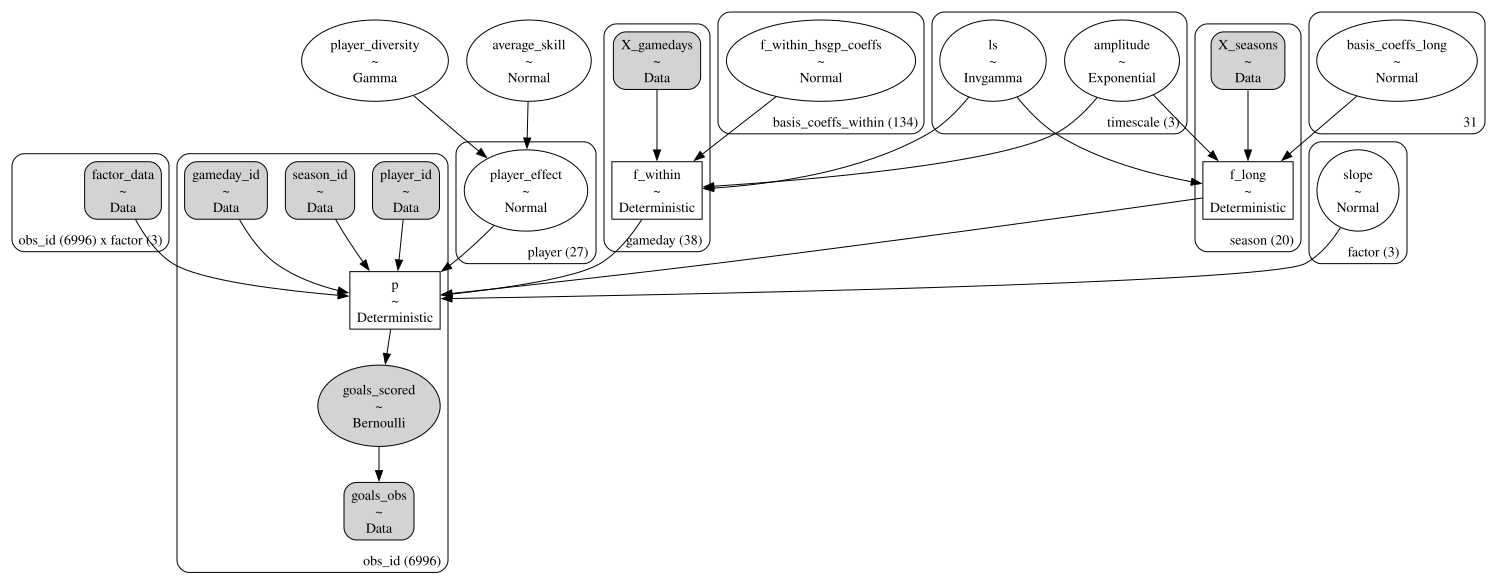

In [26]:
pm.model_to_graphviz(SFM)

### Discussion

**This is the full architecture.** Written as a generative model, for match $i$ of player $j[i]$, on matchday $d_i$, after $s_i$ seasons already played in these leagues, with standardized team factors $\mathbf{x}_i$:

$$
\begin{aligned}
y_i &\sim \mathrm{Bernoulli}(p_i) \\
\mathrm{logit}(p_i) &= \underbrace{\alpha_{j[i]}}_{\text{player skill}} + \underbrace{f_{\text{within}}(d_i)}_{\text{form within season}} + \underbrace{f_{\text{long}}(s_i)}_{\text{career stage}} + \underbrace{\mathbf{x}_i^\top \boldsymbol{\beta}}_{\text{team factors}} \\[6pt]
\alpha_j &\sim \mathrm{Normal}(\mu,\ \sigma) \\
\mu &\sim \mathrm{Normal}, \quad 89\% \text{ between } \mathrm{logit}(0.15) \text{ and } \mathrm{logit}(0.5) \\
\sigma &\sim \mathrm{Gamma}, \quad 89\% \text{ between } 0.1 \text{ and } 2 \\[6pt]
f_{\text{within}} &\sim \mathcal{GP}\big(0,\ \eta_{\text{short}}^2\, k(\cdot\,;\ \ell_{\text{short}}) + \eta_{\text{medium}}^2\, k(\cdot\,;\ \ell_{\text{medium}})\big) \\
f_{\text{long}} &\sim \mathcal{GP}\big(0,\ \eta_{\text{long}}^2\, k(\cdot\,;\ \ell_{\text{long}})\big) \\
\eta_t &\sim \mathrm{Exponential}, \quad P(\eta_t > 1.1) = 1\% \\
\ell_t &\sim \mathrm{InverseGamma}, \quad 89\% \text{ between } 2\text{-}5 \text{ matchdays (short)},\ 15\text{-}25 \text{ (medium)},\ 2\text{-}6 \text{ seasons (long)} \\[6pt]
\beta_k &\sim \mathrm{Normal}(0,\ 0.25)
\end{aligned}
$$

where $k$ is the Matérn 5/2 kernel. In code, both GPs use the HSGP approximation, $f(x) \approx \sum_m \phi_m(x)\, \sqrt{S(\sqrt{\lambda_m})}\; z_m$ with $z_m \sim \mathrm{Normal}(0, 1)$: fixed basis functions $\phi_m$, weighted by the kernel's spectral density $S$.

- $\alpha_j$ (`player_effect`), around $\mu$ (`average_skill`) with spread $\sigma$ (`player_diversity`): "How good is this player, baseline?" This is the only **partially pooled** part: each player has his own skill, shrunk toward the average.
- $f_{\text{within}}$ (`f_within`): "When in the season do goals come?" One curve over matchdays, **shared by all players**.
- $f_{\text{long}}$ (`f_long`): "How does scoring evolve as players spend more seasons here?" One curve over seasons, also **shared by all players**.
- $\mathbf{x}_i^\top \boldsymbol{\beta}$ (`slope`): "How much is team strength / home advantage helping?"
- $\eta$ (`amplitude`) and $\ell$ (`ls`): how big and how fast the GP swings are.

**The key insight**: By including team factors ($\mathbf{x}\boldsymbol{\beta}$), what's left in $\alpha$ is *individual skill*, stripped of the team context we measured (here, only 3 factors). That's our "alpha", just like in finance.

**Question for the group:** What other factors would you want to include if you had the data?

In [27]:
# Prior predictive check for the full model
with SFM:
    prior_sfm = pm.sample_prior_predictive(draws=500, random_seed=rng)

Sampling: [amplitude, average_skill, basis_coeffs_long, f_within_hsgp_coeffs, goals_scored, ls, player_diversity, player_effect, slope]


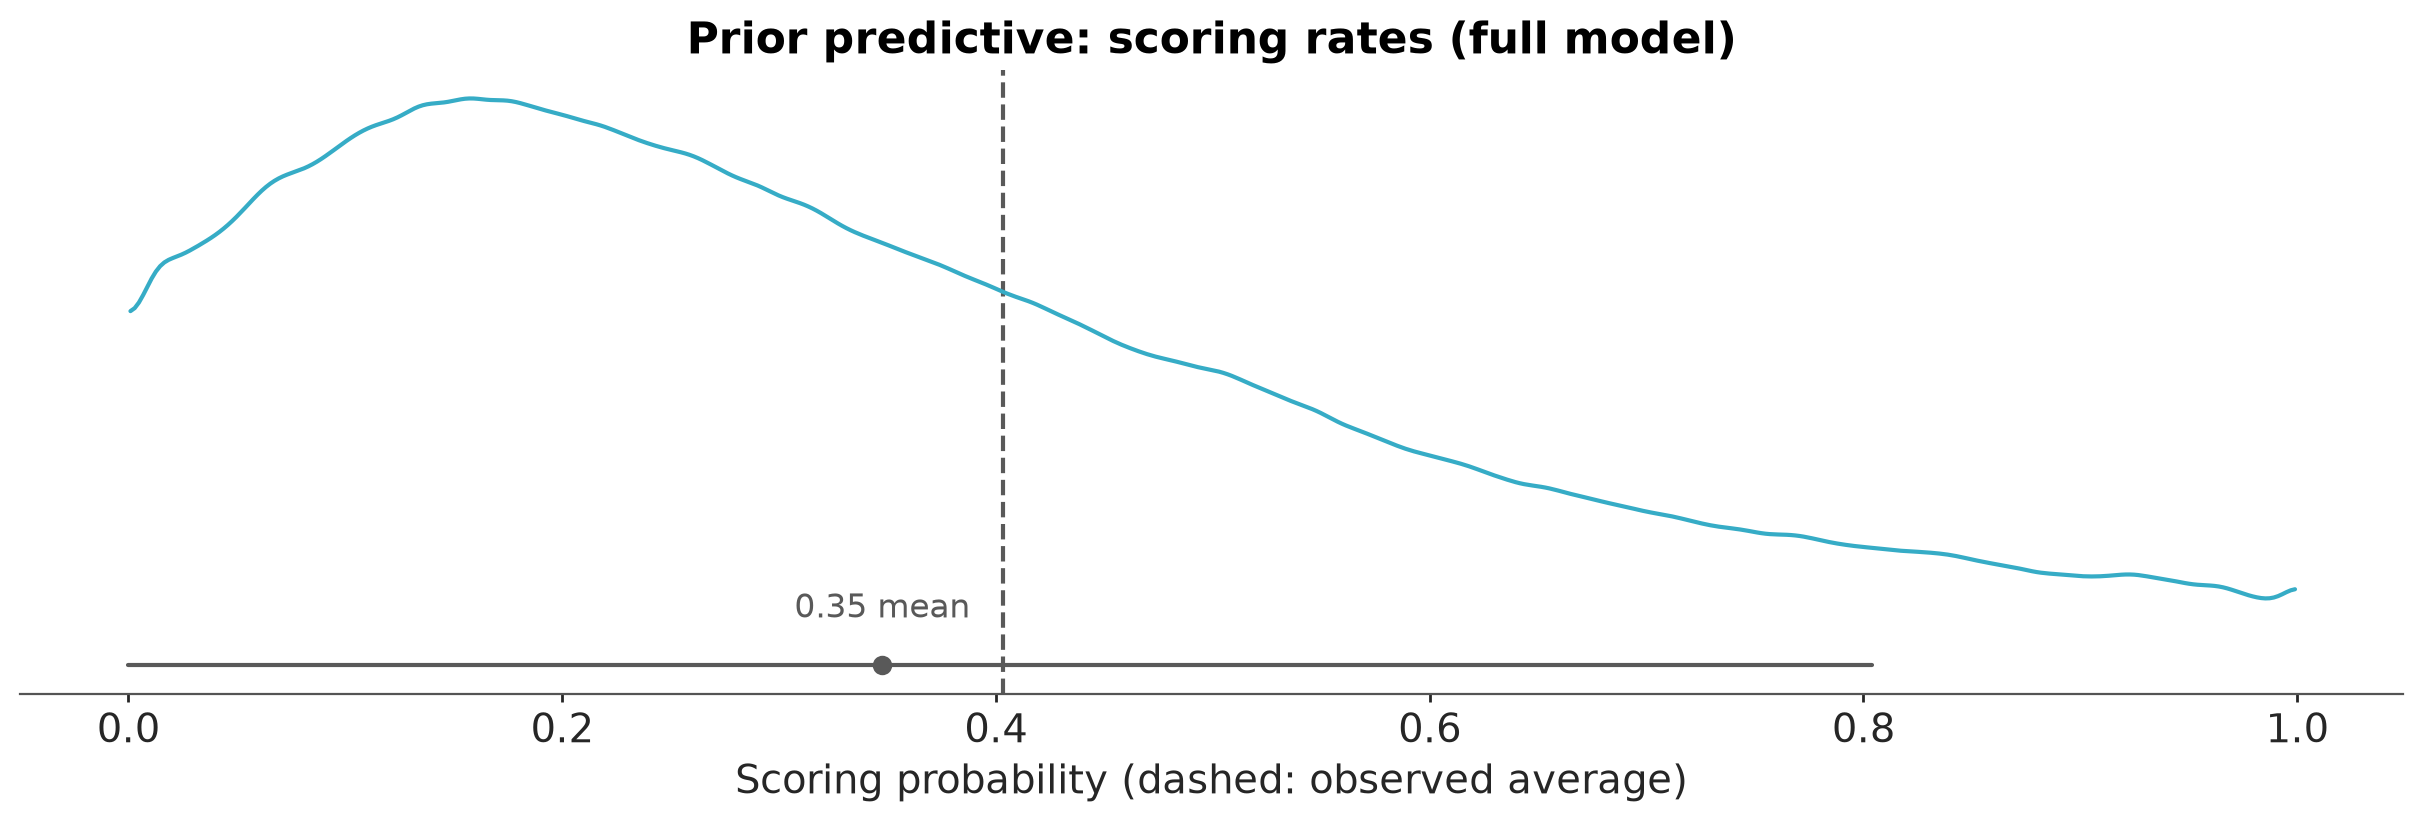

In [28]:
pc = azp.plot_dist(
    prior_sfm, group="prior", var_names="p", sample_dims=["chain", "draw", "obs_id"], figure_kwargs={"figsize": (12, 4)}
)
azp.add_lines(pc, train_data["goal"].mean(), color="C1", linestyle="--")
pc.viz["plot"]["p"].item().set(
    xlabel="Scoring probability (dashed: observed average)", title="Prior predictive: scoring rates (full model)"
);

In [29]:
# Sample the full model!
# This takes a few minutes -- a good time for questions
with SFM:
    idata_sfm = pm.sample(**sampler_kwargs(target_accept=0.99))
    idata_sfm.update(prior_sfm)

NUTS[nutpie]: [average_skill, player_diversity, player_effect, amplitude, ls, f_within_hsgp_coeffs, basis_coeffs_long, slope]


Output()

In [30]:
# First-pass convergence check for full model
azs.diagnose(idata_sfm);

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


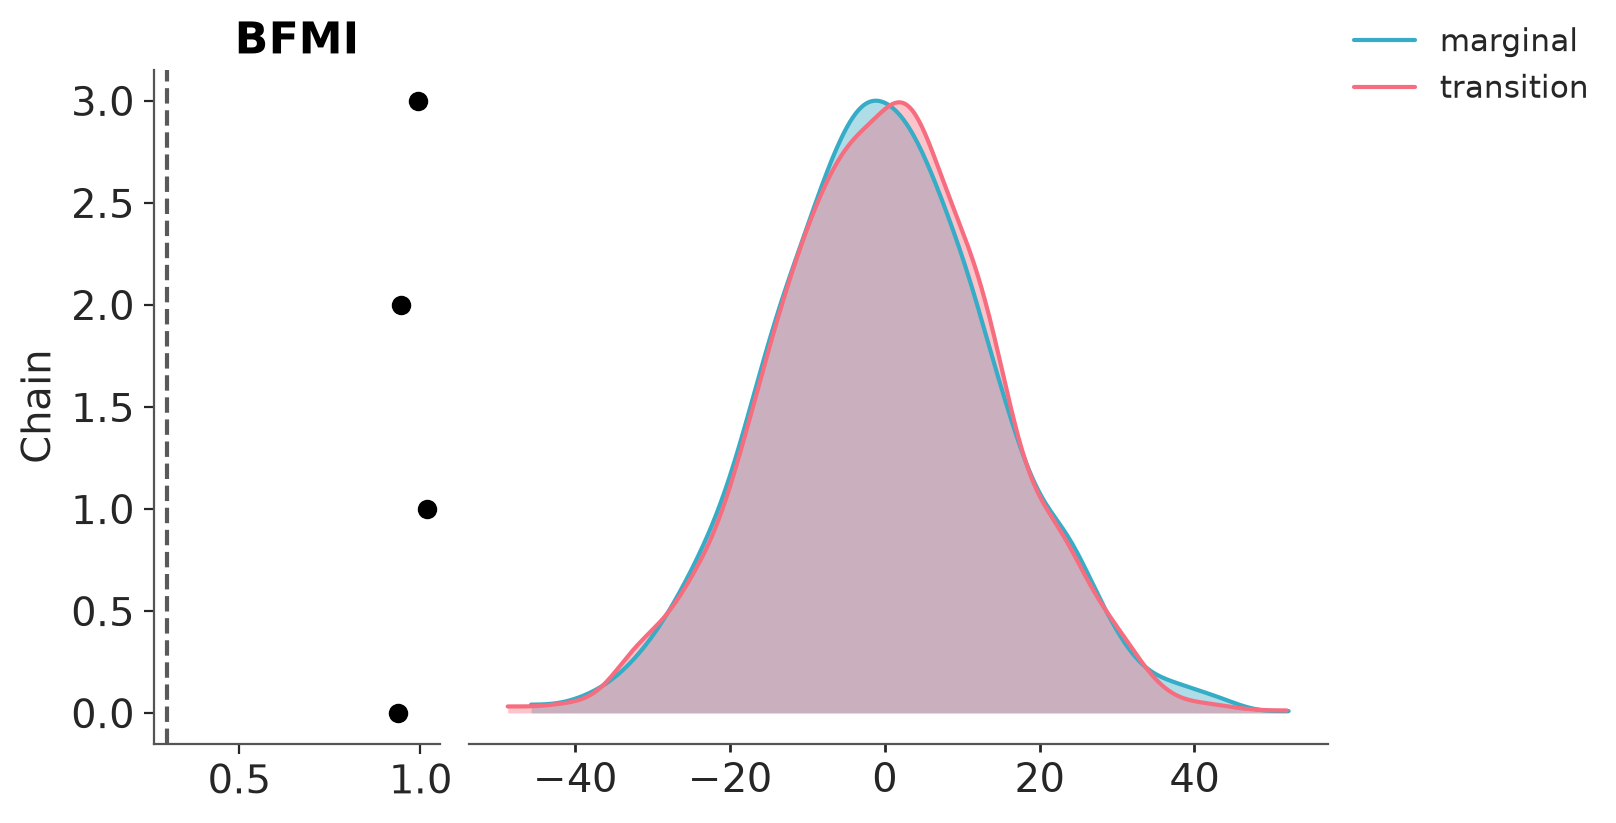

In [31]:
azp.plot_energy(idata_sfm, figure_kwargs={"figsize": (8, 4)});

### Results: Scoring rate

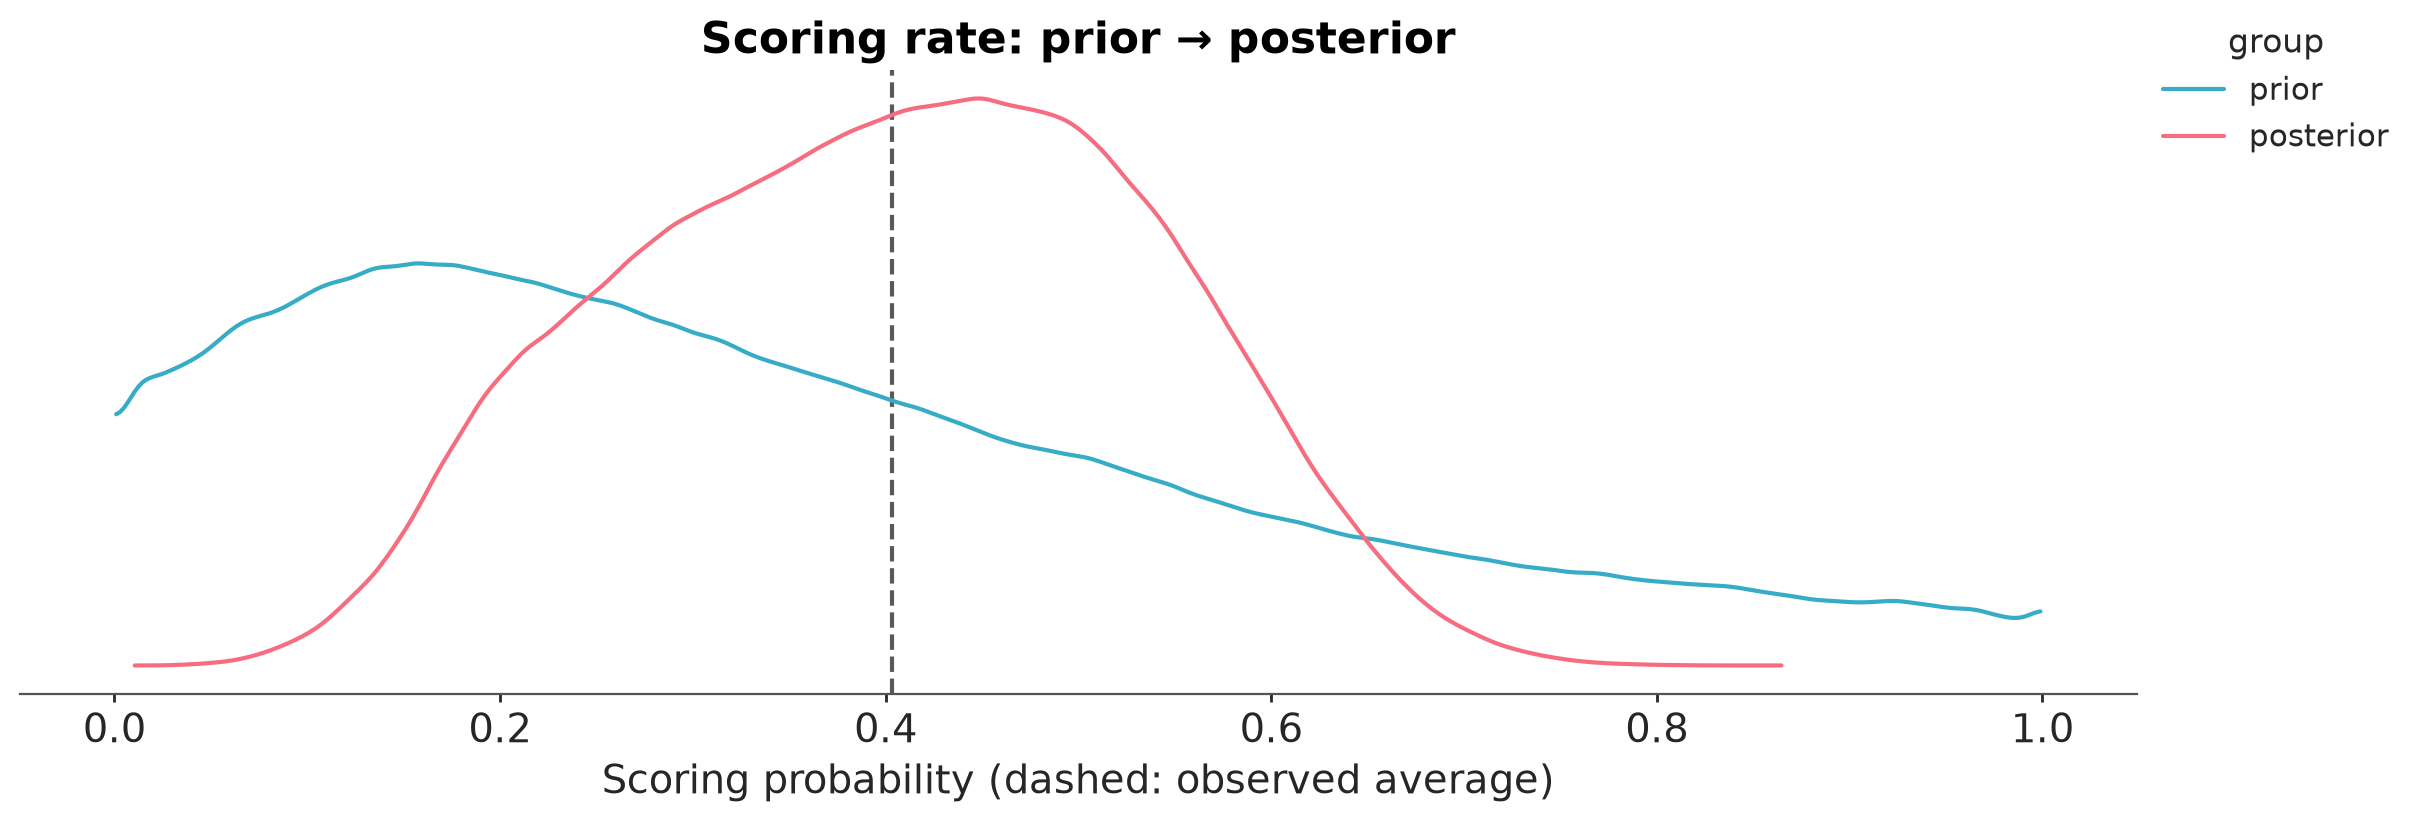

In [32]:
# only keep `p`: plot_prior_posterior gets very slow on all of the full model's variables
scoring_rate = xr.DataTree.from_dict({group: idata_sfm[group]["p"].to_dataset() for group in ("prior", "posterior")})

pc = azp.plot_prior_posterior(
    scoring_rate, var_names="p", sample_dims=["chain", "draw", "obs_id"], figure_kwargs={"figsize": (12, 4)}
)
azp.add_lines(pc, train_data["goal"].mean(), color="C2", linestyle="--")
pc.viz["plot"]["p"].item().set(
    xlabel="Scoring probability (dashed: observed average)", title="Scoring rate: prior → posterior"
);

### Results: Team Factors

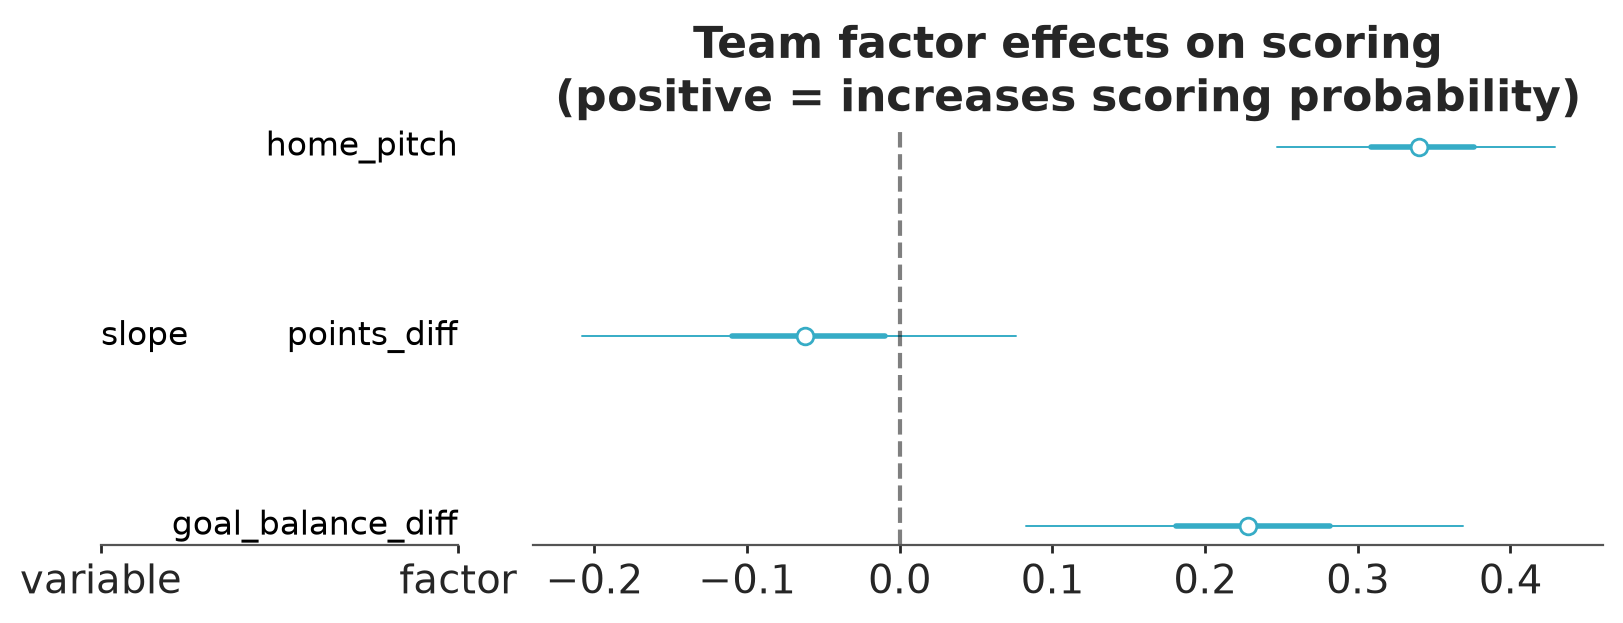

In [33]:
pc = azp.plot_forest(idata_sfm, var_names="slope", combined=True, figure_kwargs={"figsize": (8, 3)})
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(0, ls="--", color="k", alpha=0.5)
ax.set(title="Team factor effects on scoring\n(positive = increases scoring probability)");

### Discussion

> **Interpreting the factors:**
> - `home_pitch`: Does playing at home increase scoring? By how much?
> - `points_diff`: When your team is ahead in the standings, does that help?
> - `goal_balance_diff`: When your team scores more than the opponent overall, does that boost individual scoring?
>
> These are the "team effects" we're stripping out to isolate individual skill.

### Results: Player Skills (Now With Temporal Dynamics!)

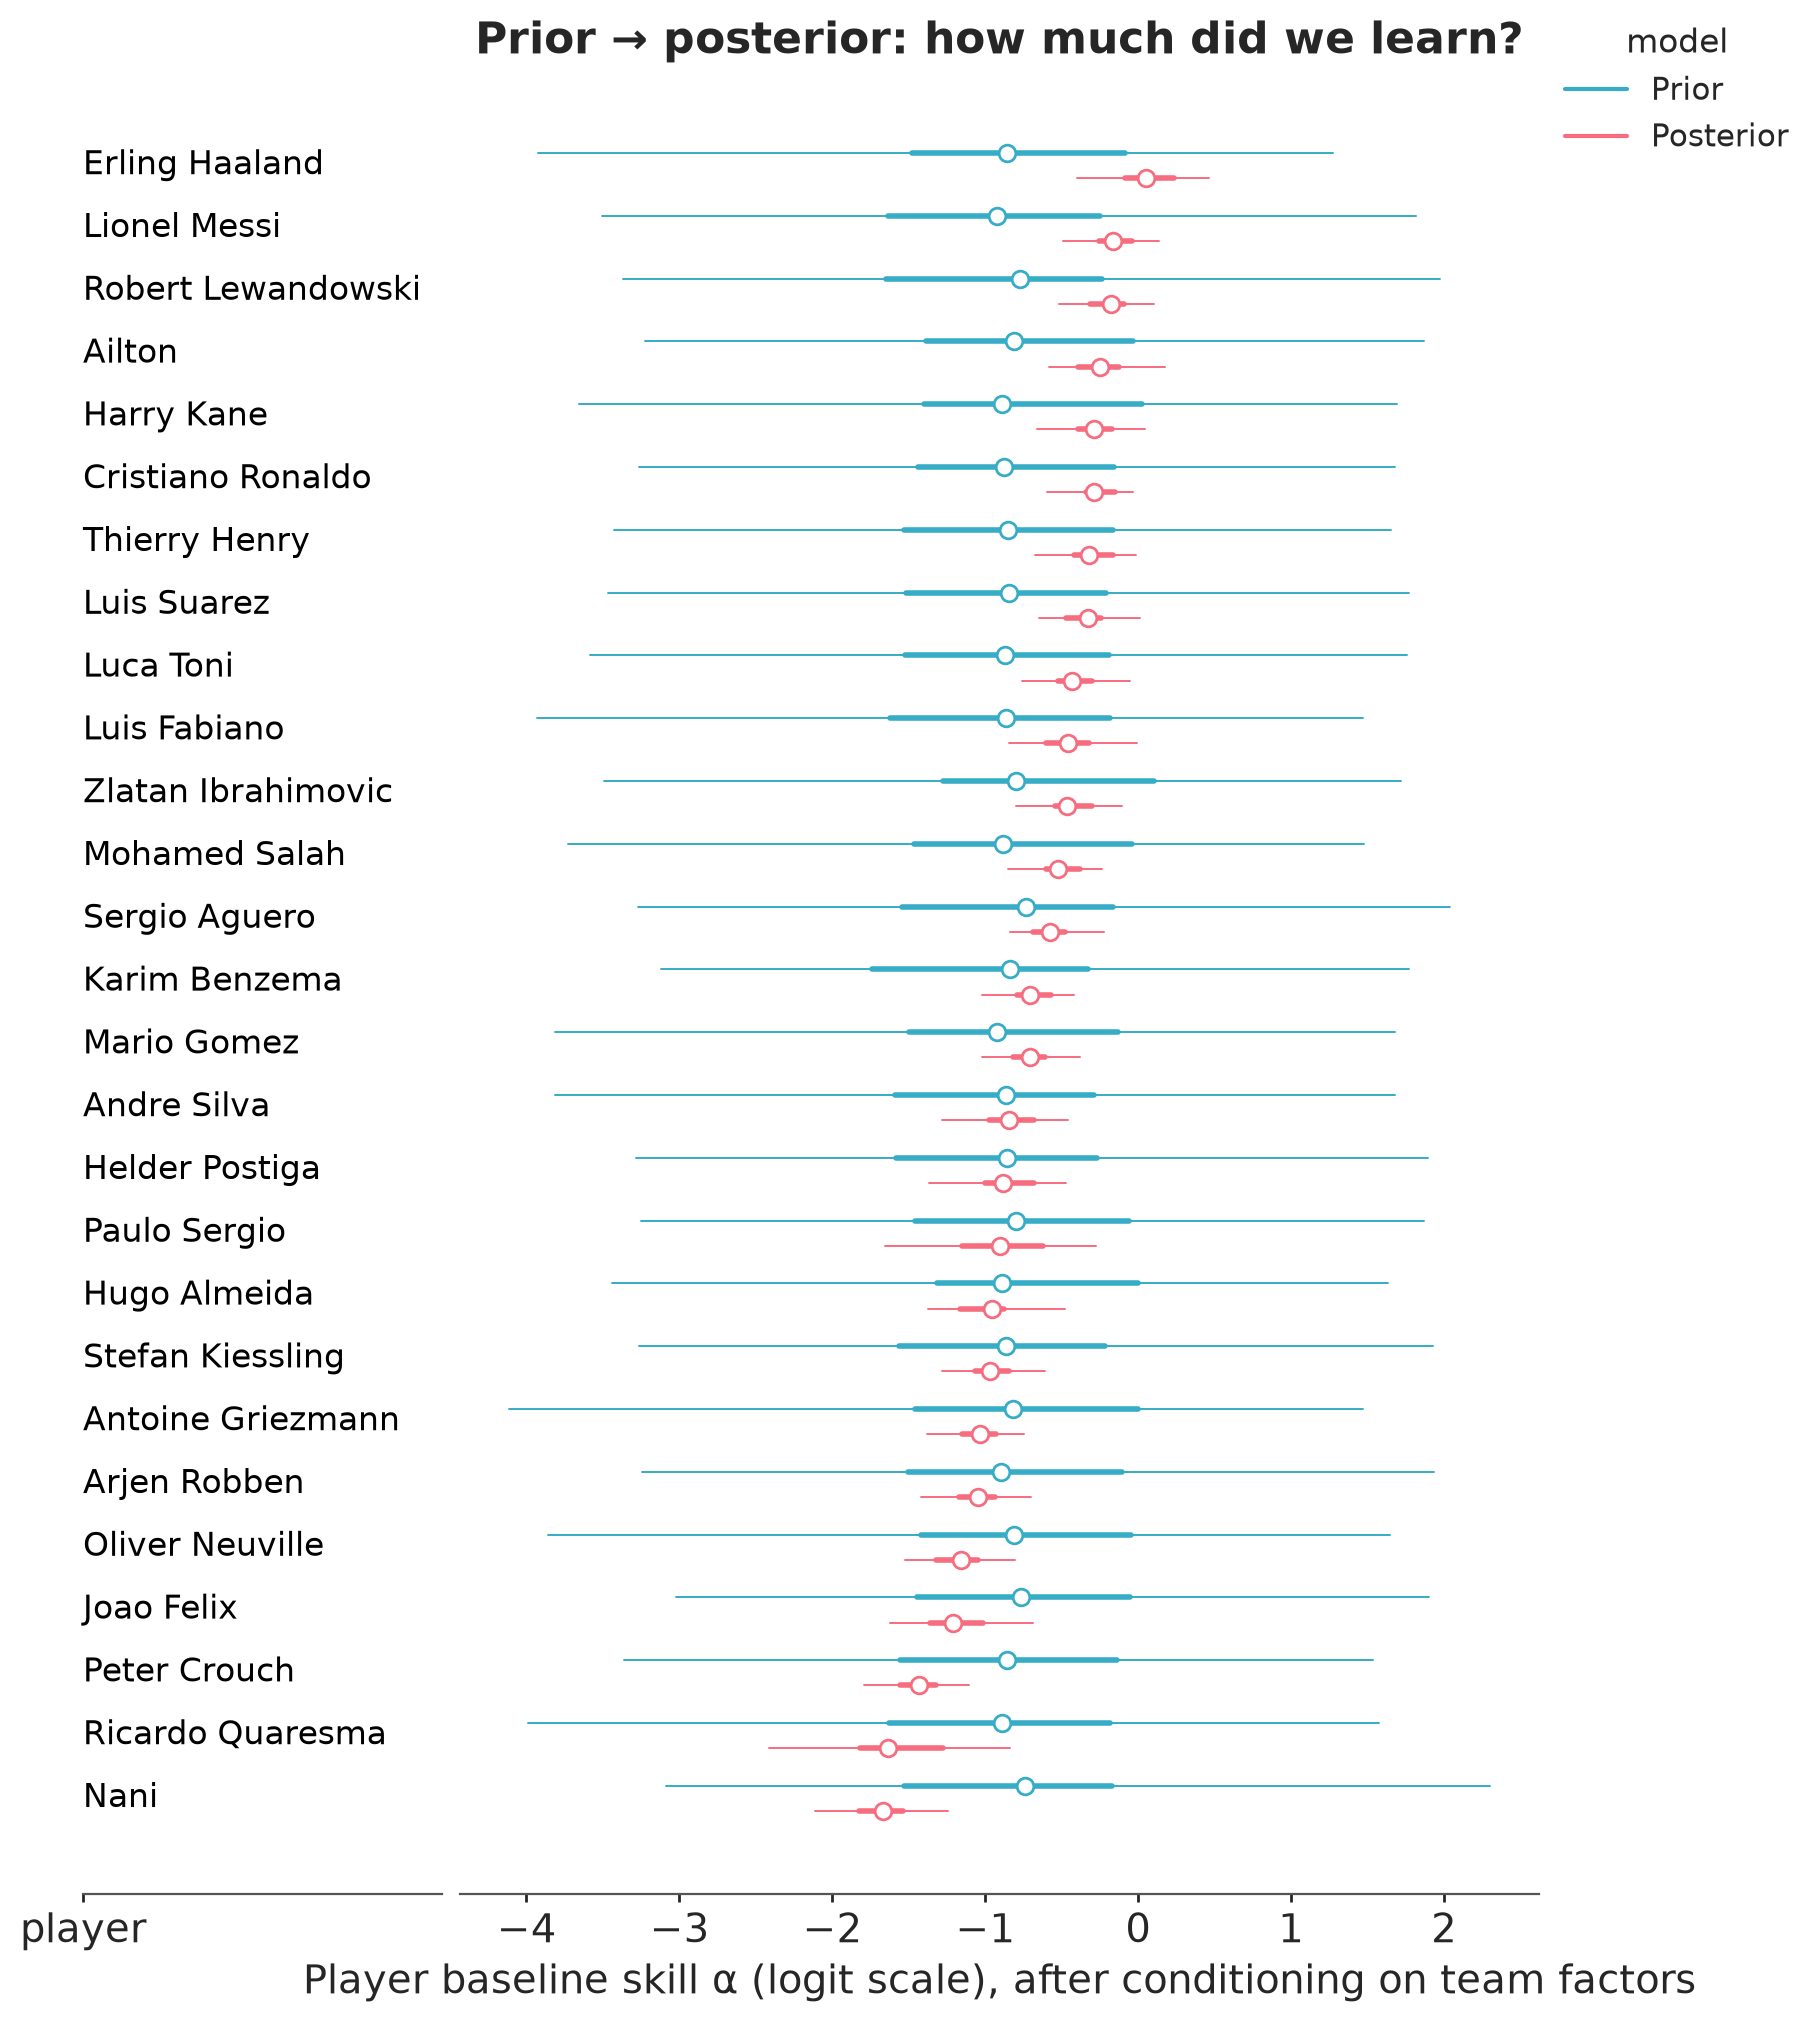

In [34]:
by_skill = idata_sfm.posterior["player_effect"].mean(("chain", "draw")).to_series().sort_values(ascending=False).index

# 500 random draws from each group, so prior and posterior have the same shape
# (we drop the chain/draw labels, which the two groups don't share)
skill_draws = {
    group.title(): az.extract(idata_sfm, group=group, var_names="player_effect", num_samples=500, random_seed=rng)
    .drop_vars(["sample", "chain", "draw"])
    .sel(player=by_skill)
    .to_dataset()
    for group in ("prior", "posterior")
}

pc = azp.plot_forest(skill_draws, sample_dims=["sample"], combined=True, labels=["player"])
pc.add_legend("model")
pc.viz["plot"].sel(column="forest").item().set(
    xlabel="Player baseline skill α (logit scale), after conditioning on team factors",
    title="Prior → posterior: how much did we learn?",
)
pc.viz["figure"].item().set_size_inches(9, 10)

### Results: Temporal Dynamics: Career Stage and Form

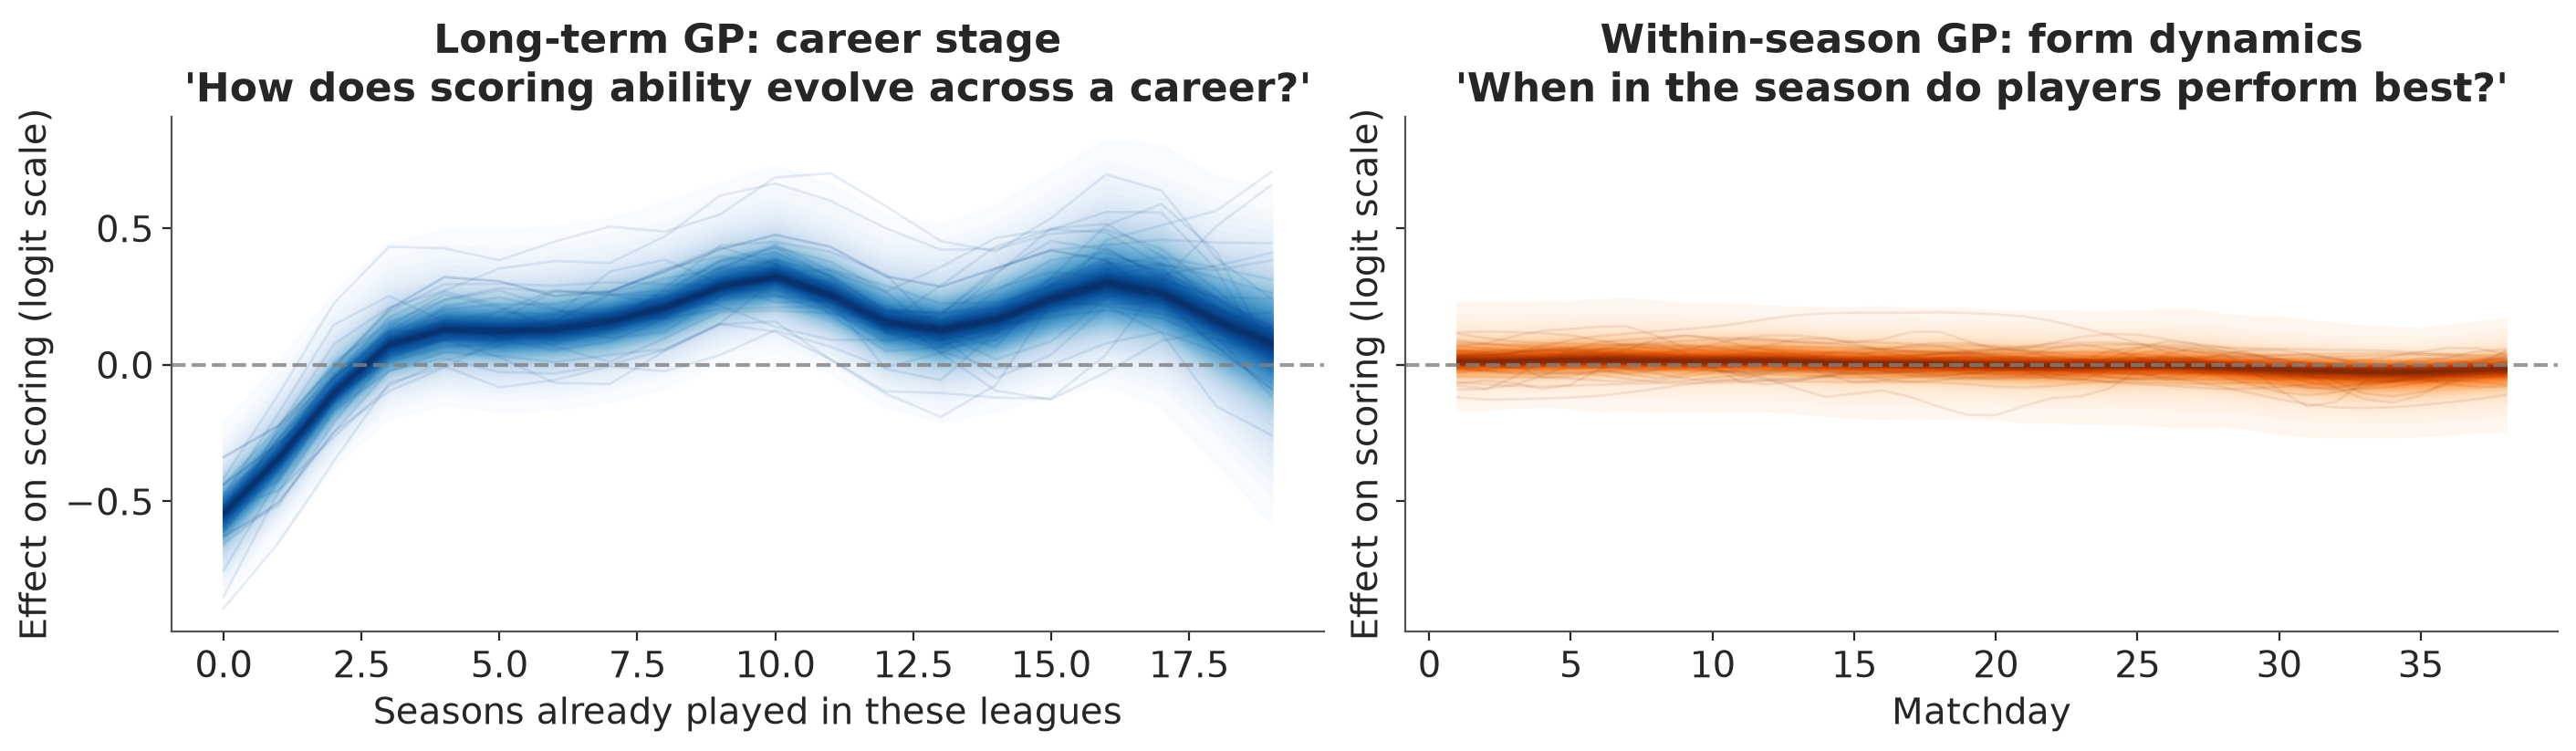

In [35]:
def draws_by(var, dim):
    """Posterior draws of `var` as a (sample, dim) array, the shape pm.gp.util.plot_gp_dist expects"""
    return idata_sfm.posterior[var].stack(sample=("chain", "draw")).transpose("sample", dim).to_numpy()


fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True, sharey=True)

pm.gp.util.plot_gp_dist(axes[0], draws_by("f_long", "season"), seasons, palette="Blues")
axes[0].axhline(0, color="grey", ls="--", alpha=0.8)
axes[0].set(
    xlabel="Seasons already played in these leagues",
    ylabel="Effect on scoring (logit scale)",
    title="Long-term GP: career stage\n'How does scoring ability evolve across a career?'",
)

pm.gp.util.plot_gp_dist(axes[1], draws_by("f_within", "gameday"), gamedays, palette="Oranges")
axes[1].axhline(0, color="grey", ls="--", alpha=0.8)
axes[1].set(
    xlabel="Matchday",
    ylabel="Effect on scoring (logit scale)",
    title="Within-season GP: form dynamics\n'When in the season do players perform best?'",
);

### Discussion

> **The GPs tell us interesting things:**
> - **Career stage** (left): scoring climbs over a player's first ~3 seasons in these leagues, then roughly plateaus. Does that match your intuition?
> - **Within-season** (right): flat around zero: across all players, there's no part of the season where scoring systematically changes.
>
> The shaded bands are posterior percentiles (darker = more likely): wider = less certain.
> The career-stage band widens on the right, where few players have spent that many seasons in these leagues.

### Individual Player Scoring Probabilities Over Time

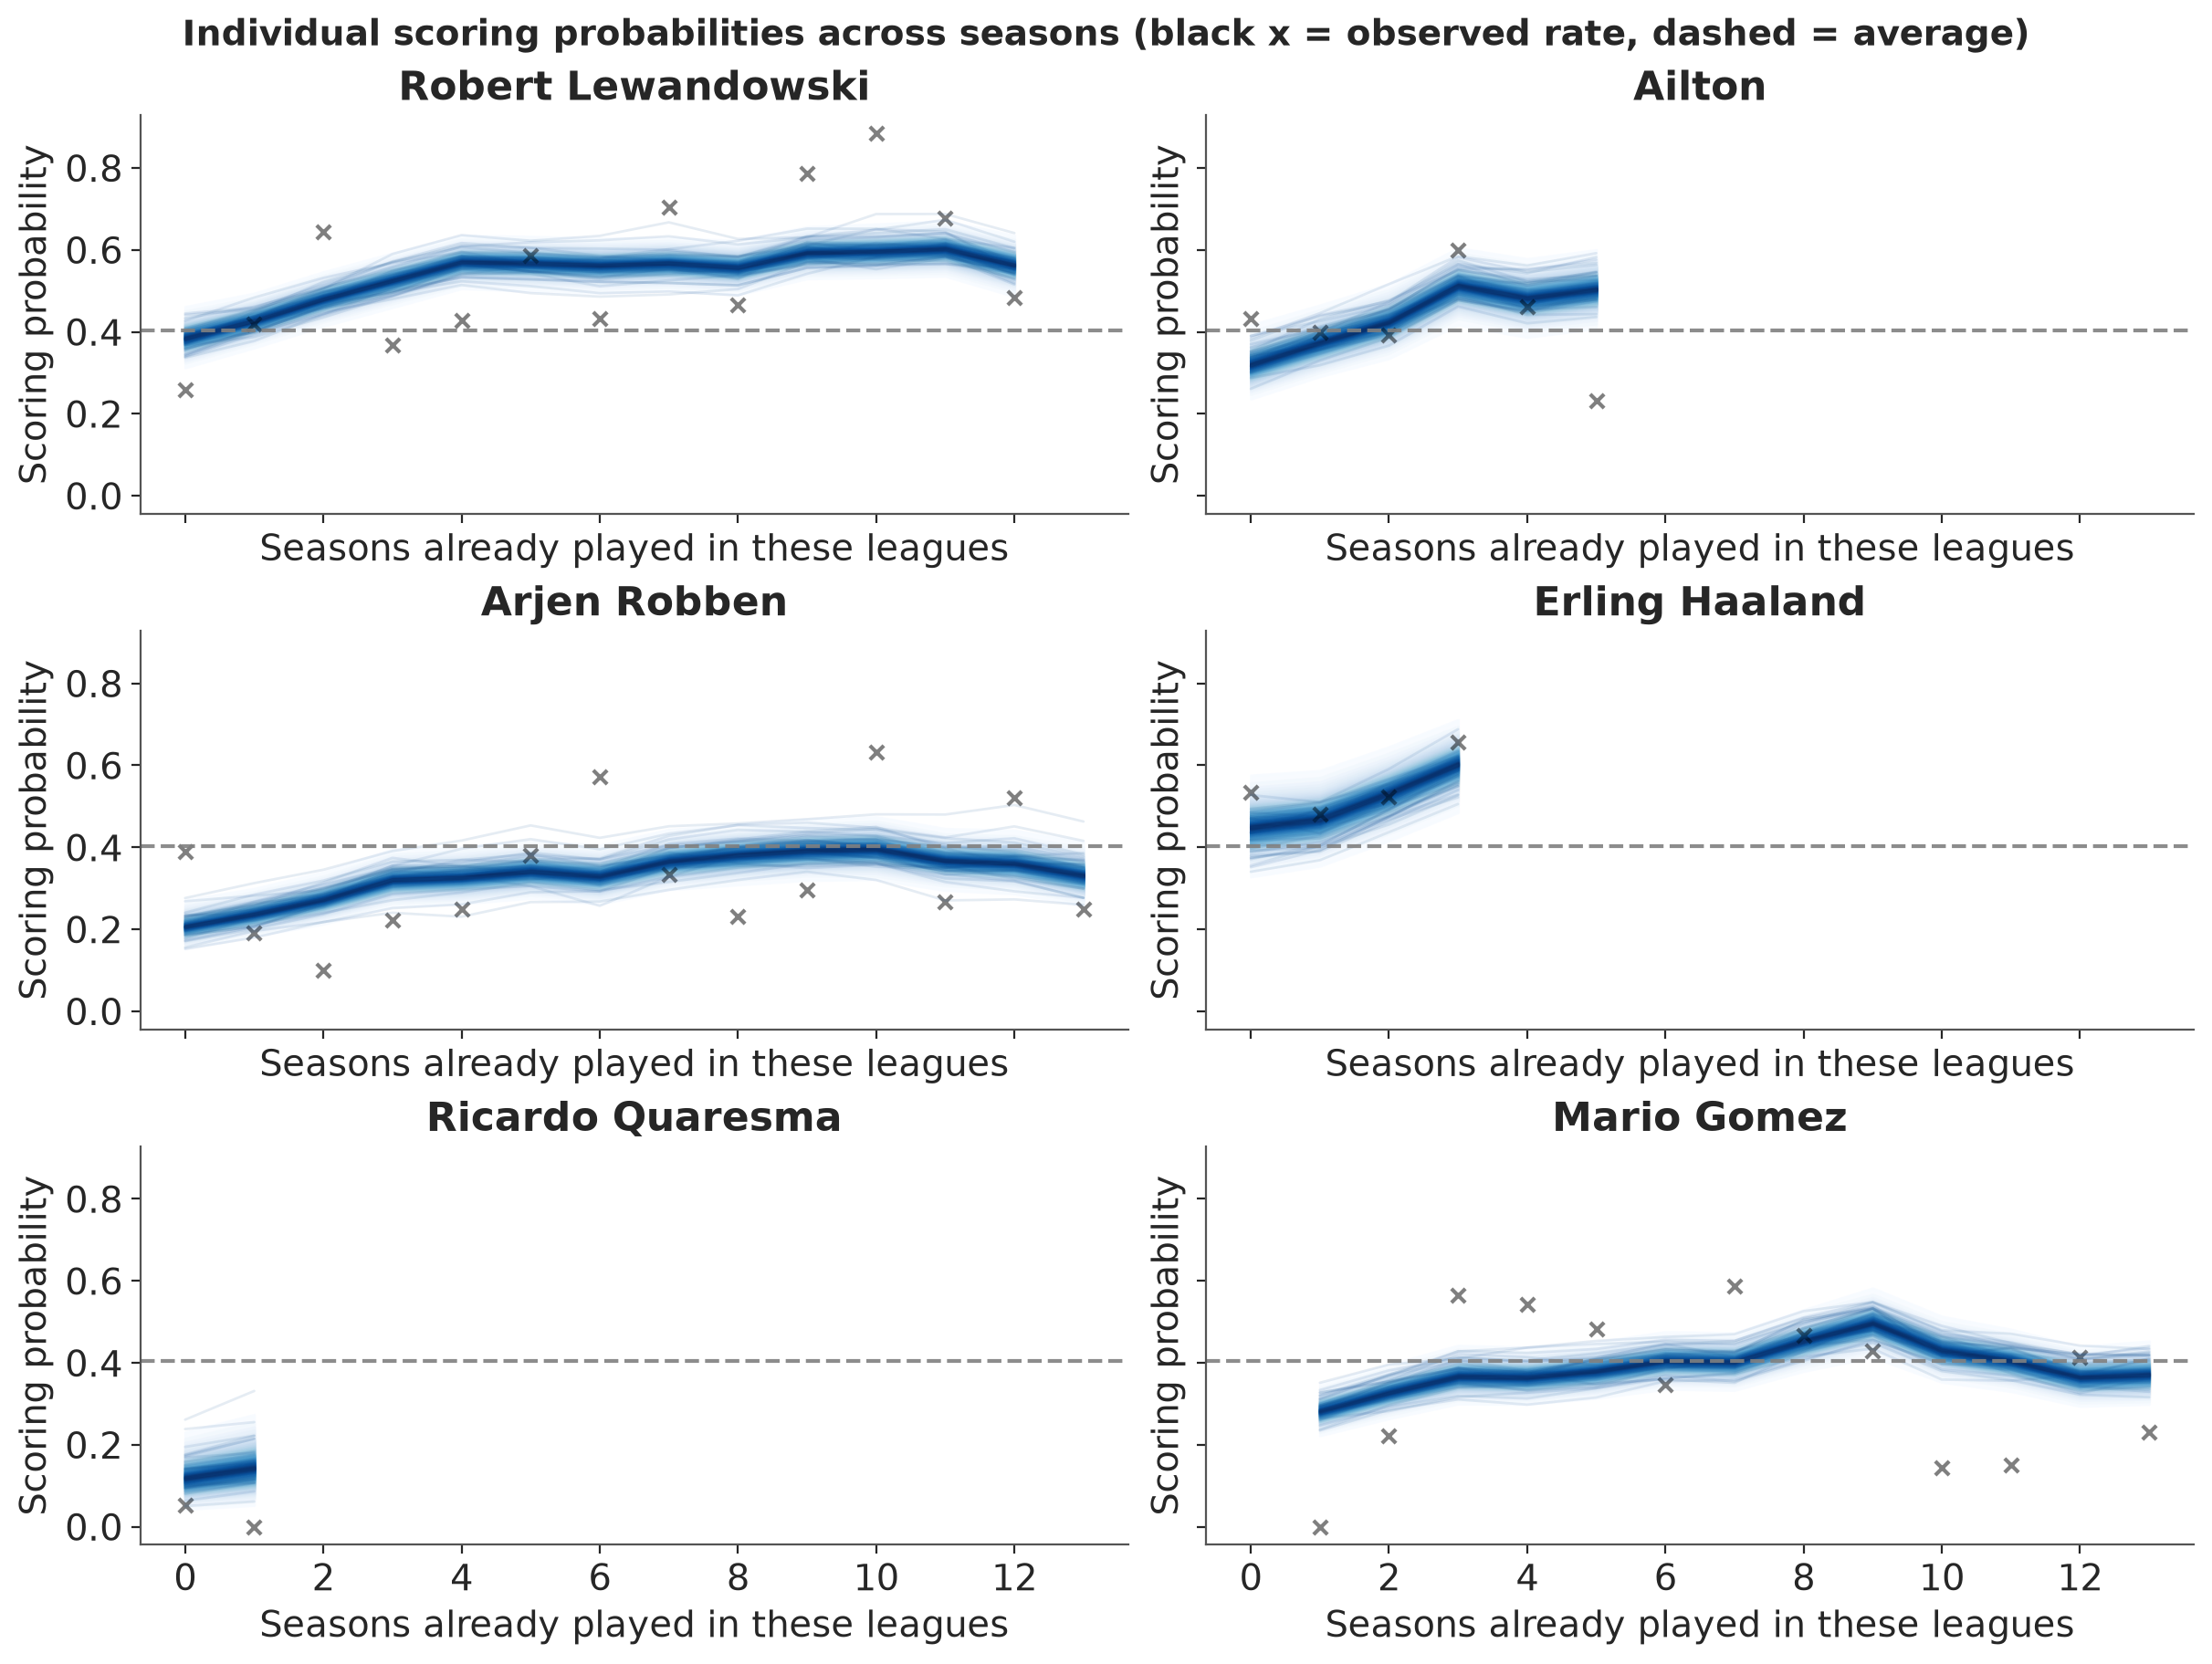

In [36]:
# Pick a few interesting players to visualize
showcase_players = ["Robert Lewandowski", "Ailton", "Arjen Robben", "Erling Haaland", "Ricardo Quaresma", "Mario Gomez"]

p_post = idata_sfm.posterior["p"].assign_coords(season_nbr=("obs_id", train_data["season_nbr"]))
observed_rates = train_data.groupby(["player", "season_nbr"])["goal"].mean()

fig, axes = plt.subplots(3, 2, figsize=(12, 9), constrained_layout=True, sharex=True, sharey=True)

for ax, player in zip(axes.flatten(), showcase_players):
    # average scoring probability over the player's matches, season by season
    player_matches = train_data.index[train_data["player"] == player]
    season_probs = p_post.sel(obs_id=player_matches).groupby("season_nbr").mean().stack(sample=("chain", "draw"))
    pm.gp.util.plot_gp_dist(
        ax,
        season_probs.transpose("sample", "season_nbr").to_numpy(),
        season_probs.season_nbr.to_numpy(),
        palette="Blues",
    )
    ax.scatter(observed_rates[player].index, observed_rates[player], marker="x", color="k", alpha=0.5, s=30)
    ax.axhline(train_data.goal.mean(), color="grey", ls="--", alpha=0.9)
    ax.set(title=player, xlabel="Seasons already played in these leagues", ylabel="Scoring probability")

fig.suptitle(
    "Individual scoring probabilities across seasons (black x = observed rate, dashed = average)", fontsize=14
);

### Discussion

> **This is where it gets actionable... and where you see the model's limits:**
> - Each curve combines the player's own skill, the *shared* career-stage curve, and his team context that season
> - So the *shape* is mostly the same for everyone (that's why Gomez and Robben both peak after 9-10 seasons in these leagues): differences come from each player's level and team context
> - Giving each player his own career curve is a natural next step
> - The grey dashed line is the average: players above it are outperforming
>
> In the full SFM, this scales to 2,850+ players across 5 leagues, with metrics like **SAR** (Skill Above Replacement) and **PAR** (Performance Above Replacement)
> that quantify individual talent independent of team context.

---
# Part 4 — The Full Picture: Separating Skill from Context

## From Model to Metrics

The model we just built is a simplified version of the **Soccer Factor Model** (SFM). The full version includes:

| Feature | Workshop Version | Full SFM |
|---|---|---|
| Players | 27 | 2,850+ |
| Leagues | 4 (Premier League, La Liga, Bundesliga, Serie A) | 5 + Champions League |
| Factors | 3 | 8+ (incl. opponent defensive rank, player momentum) |
| Outcome | Binary (goal/no goal) | Ordered categorical (0, 1, 2, 3+ goals) |
| GP timescales | 3 | 3 (same architecture) |
| Observations | ~7,000 | 42,000+ |

### Key Metrics from the Full Model

**SAR (Skill Above Replacement):**
Expected goals/game based *purely on intrinsic skill* (α), independent of team --> "How would this player score on an average team?"

**PAR (Performance Above Replacement):**
Expected goals/game with *both* skill AND team factors --> "How does this player actually perform in their current context?"

**The money insight:** When **SAR > PAR**, the player is *undervalued*: their skill is being held back by their team context. That's a buying opportunity.

## Think Like an Investor

The analogy with asset pricing is exact:

| Finance | Football |
|---|---|
| Fund return | Goals scored |
| α (manager skill) | α (player skill) |
| β × market factors | β × team factors |
| Jensen's alpha | SAR |

Just as alpha in finance measures a fund manager's skill after stripping out market-wide movements,
our α measures a player's skill after stripping out team context.

More details in the [paper](https://arxiv.org/abs/2412.05911) and on the [live platform](https://www.soccerfactormodel.com)!

## Posterior Predictive Checks (Full Model)

In [37]:
with SFM:
    pm.sample_posterior_predictive(idata_sfm, extend_inferencedata=True, random_seed=rng)
    pm.compute_log_likelihood(idata_sfm, extend_inferencedata=True)

Sampling: [goals_scored]


Output()

Output()

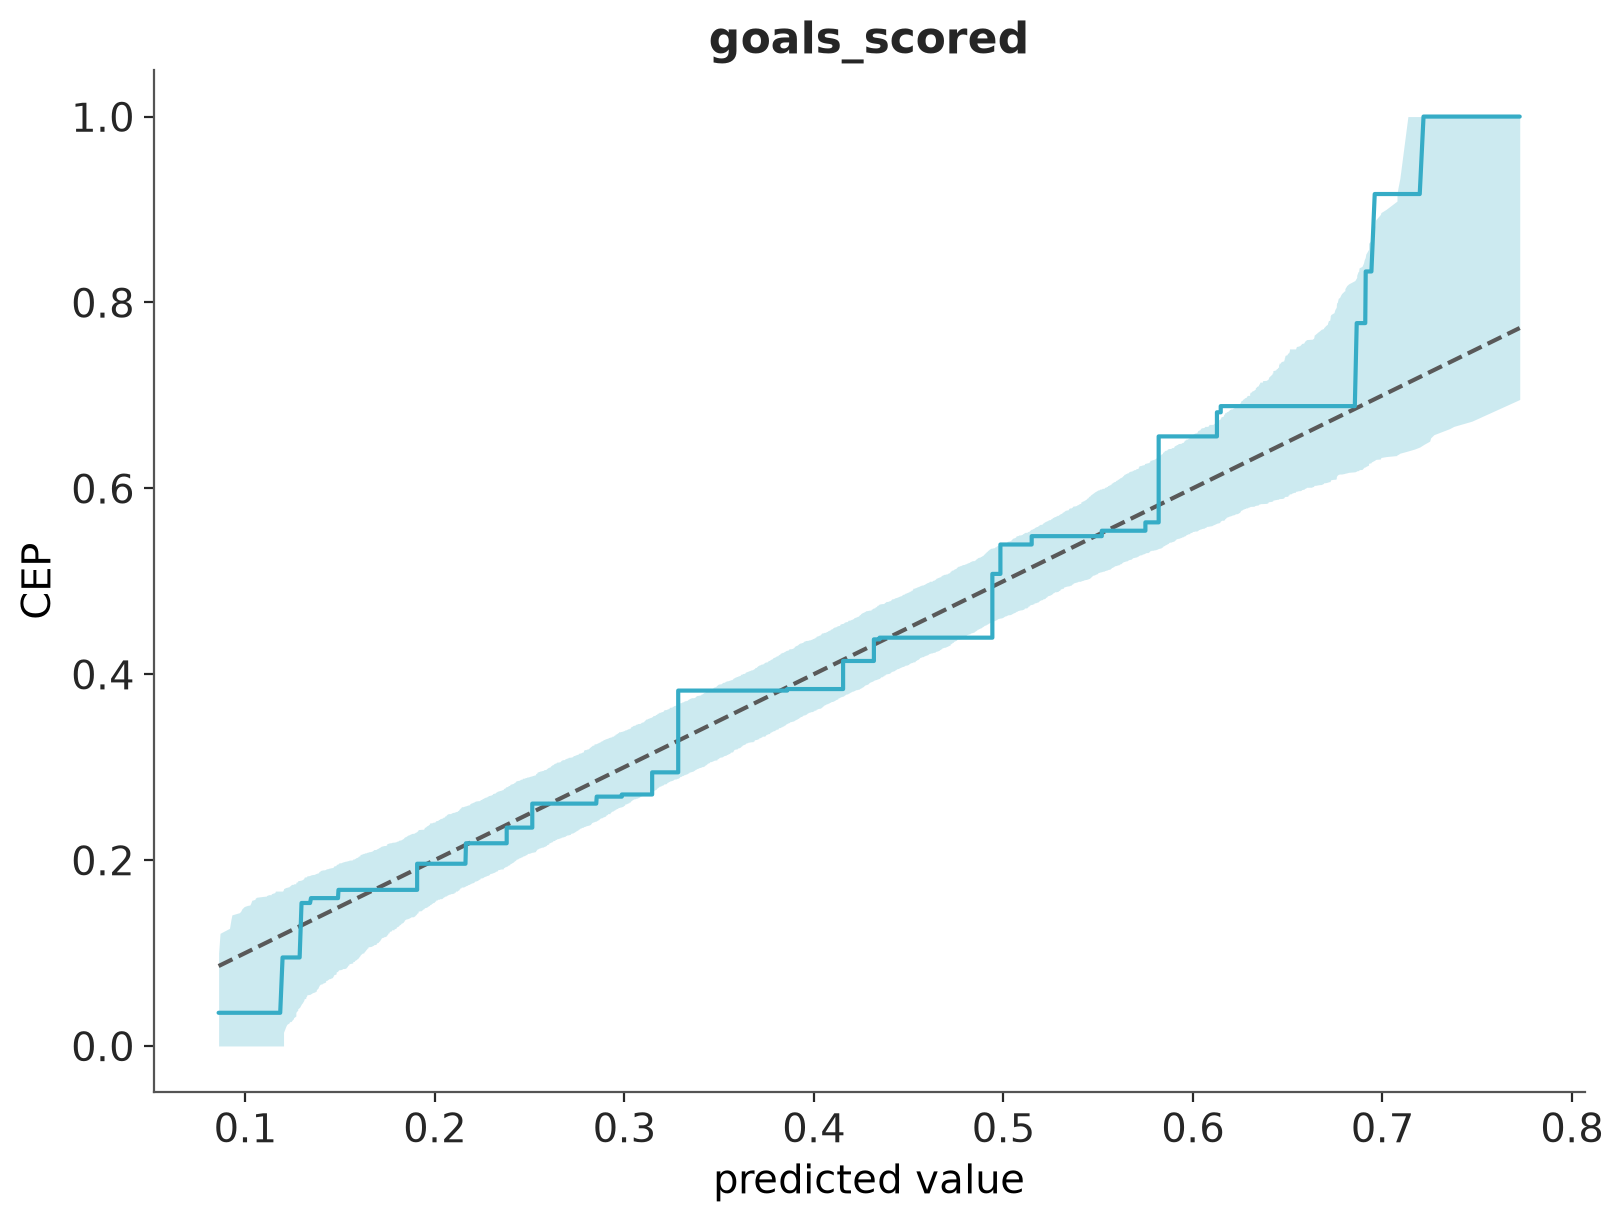

In [38]:
# Posterior predictive check: does our model generate realistic data?
azp.plot_ppc_pava(idata_sfm, figure_kwargs={"figsize": (8, 6)});

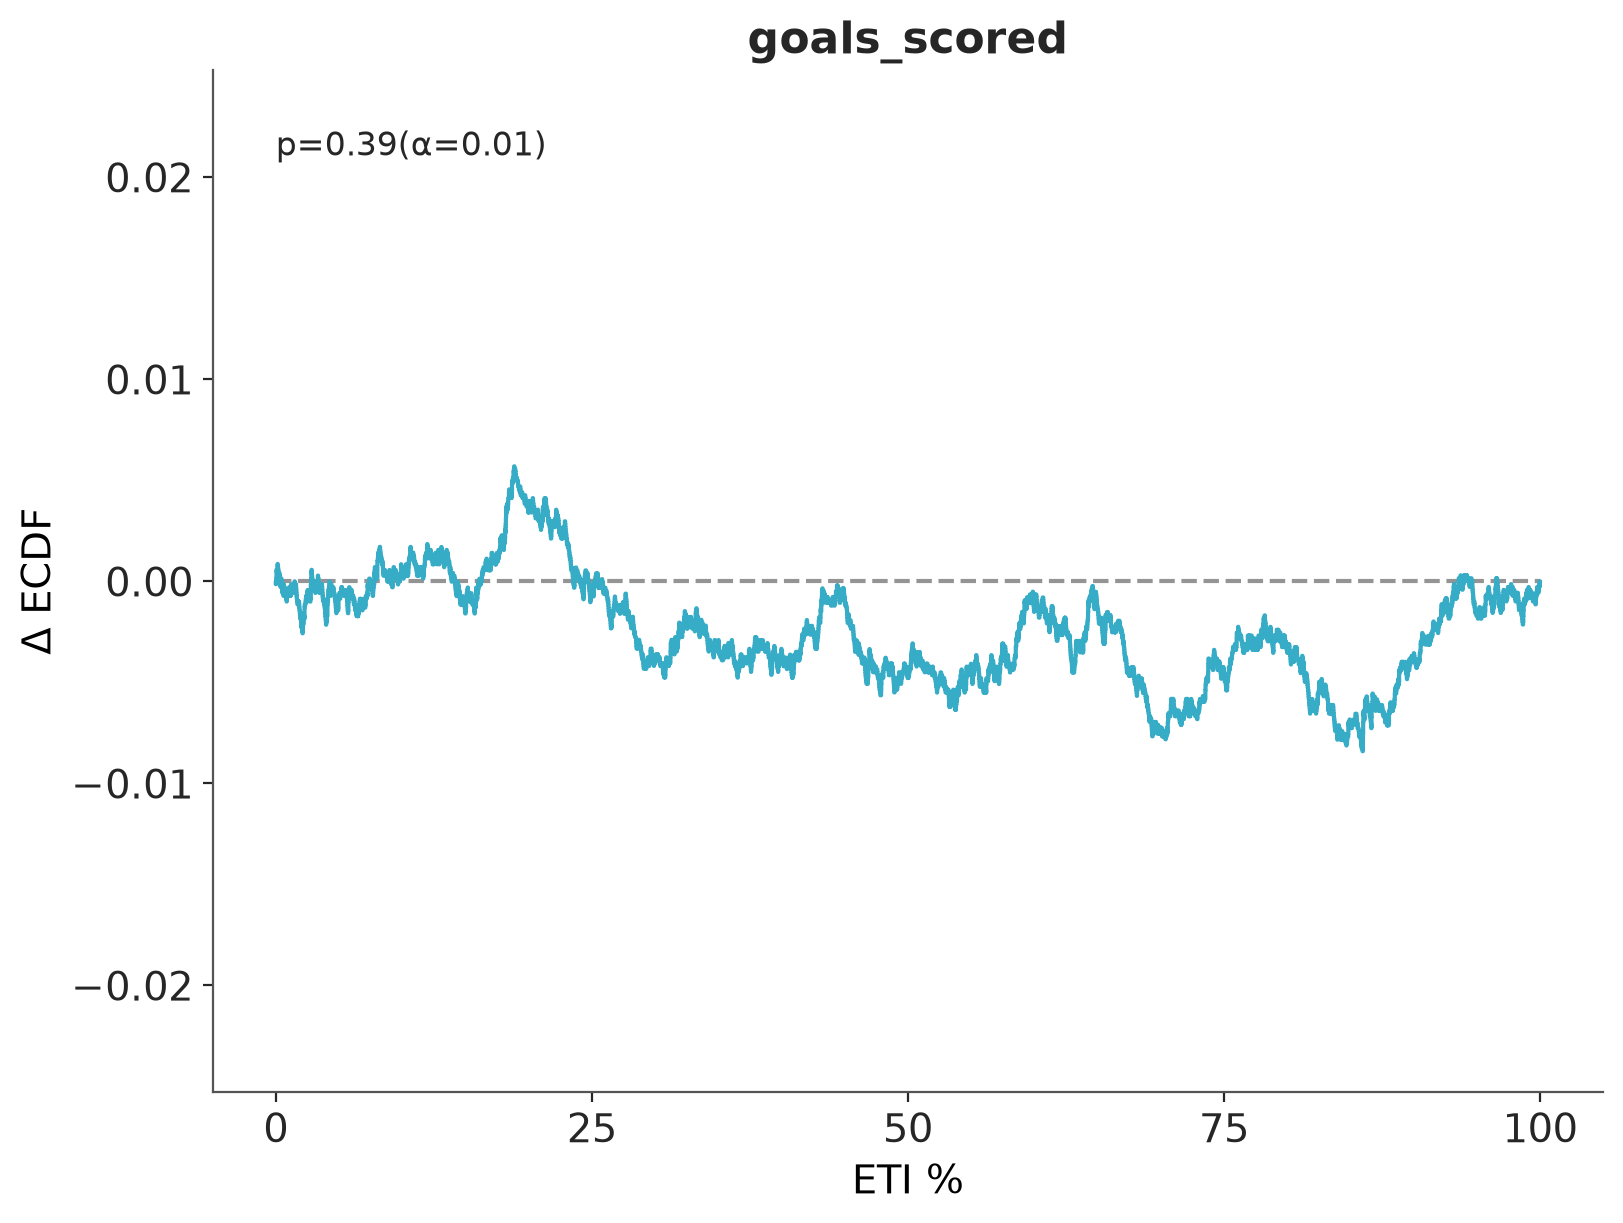

In [39]:
# LOO-PIT calibration check for the full model
azp.plot_loo_pit(idata_sfm, coverage=True, figure_kwargs={"figsize": (8, 6)});

---
# Part 5 — Does It Actually Work?

So far, we checked that our models can reproduce the matches they were trained on. But the question that matters is: **do they predict matches they have never seen?**

Two ways to answer:
1. **Leave-one-out cross-validation** (LOO-CV), which ArviZ estimates from the training data, without re-sampling the model 7,000 times
2. The **last season of each player**, which we kept aside at the very beginning

## In-sample fit vs cross-validation: a cautionary tale

A little story from our own research first. When building the full SFM, we tried giving **each player his own sensitivity to some team factors**. In-sample, it looked amazing. Under cross-validation, it collapsed.

The lesson: **a better fit to the data you trained on doesn't mean better predictions.** Adding parameters always improves the fit in-sample; only out-of-sample checks tell you whether the extra complexity captured something real, or just noise.

Let's reproduce that on a small scale. To keep it fast, we drop the GPs and keep player skill + the three team factors, in two versions:
- **one slope per factor, shared by all players**, like in the full model above
- **one slope per player and per factor** (27 × 3 = 81 slopes instead of 3), each free to move: Normal(0, 1) priors, 4 times wider than the shared slope's Normal(0, 0.25), and not pooled across players

In [40]:
def skill_and_factors_model(per_player_slopes):
    """Player skill + team factors, no GPs: one slope per factor, or one per player and factor"""
    with pm.Model(coords=coords) as model:
        player_id = pm.Data("player_id", player_idx, dims="obs_id")
        factor_data = pm.Data("factor_data", factors_sdz.to_numpy(), dims=("obs_id", "factor"))
        goals_obs = pm.Data("goals_obs", train_data["goal"].to_numpy(), dims="obs_id")

        average_skill = average_skill_dist.to_pymc("average_skill")
        sigma = player_diversity_dist.to_pymc("player_diversity")
        player_effect = pm.Normal("player_effect", mu=average_skill, sigma=sigma, dims="player")

        if per_player_slopes:
            # each player reacts to team context in his own way
            slope = pm.Normal("slope", sigma=1.0, dims=("player", "factor"))
            team_effect = (factor_data * slope[player_id]).sum(axis=1)
        else:
            # same reaction to team context for everybody
            slope = pm.Normal("slope", sigma=0.25, dims="factor")
            team_effect = pm.math.dot(factor_data, slope)

        p = pm.Deterministic("p", pm.math.sigmoid(player_effect[player_id] + team_effect), dims="obs_id")
        pm.Bernoulli("goals_scored", p=p, observed=goals_obs, dims="obs_id")

    return model


def sample(model):
    """Sample the posterior, then compute the log-likelihood that LOO-CV needs"""
    with model:
        idata = pm.sample(**sampler_kwargs())
        pm.compute_log_likelihood(idata, extend_inferencedata=True)
    return idata


shared_slopes_model = skill_and_factors_model(per_player_slopes=False)
per_player_slopes_model = skill_and_factors_model(per_player_slopes=True)

idata_shared_slopes = sample(shared_slopes_model)
idata_per_player_slopes = sample(per_player_slopes_model)

NUTS[nutpie]: [average_skill, player_diversity, player_effect, slope]


Output()

Output()

NUTS[nutpie]: [average_skill, player_diversity, player_effect, slope]


Output()

Output()

In [41]:
tale = {"Shared slopes": idata_shared_slopes, "Per-player slopes": idata_per_player_slopes}

for name, idata in tale.items():
    print(f"── {name} ──")
    azs.diagnose(idata)

── Shared slopes ──


Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.
── Per-player slopes ──


Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


In [42]:
loo_results = {name: azs.loo(idata) for name, idata in tale.items()}

pd.DataFrame(
    {
        # in-sample fit (log pointwise predictive density) = LOO-CV estimate + effective number of parameters
        "in-sample fit": {name: loo.elpd + loo.p for name, loo in loo_results.items()},
        "LOO-CV (elpd_loo)": {name: loo.elpd for name, loo in loo_results.items()},
        "effective parameters (p_loo)": {name: loo.p for name, loo in loo_results.items()},
    }
).round(1)

,in-sample fit,LOO-CV (elpd_loo),effective parameters (p_loo)
Shared slopes,-4478.7,-4505.8,27.1
Per-player slopes,-4435.3,-4524.9,89.7


Bingo! The per-player slopes fit the training matches better (higher in-sample fit), but predict *unseen* matches worse (lower LOO-CV). Look at the last column: about 90 effective parameters instead of 27, so most of that extra flexibility went into **fitting noise**, not signal.

**In-sample fit rewards complexity; cross-validation rewards signal.**

## Comparing all the models

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Full SFM,0,0.0,0.0,NaN,,,35.6,-4470.0,26.0,0.86
Skill + shared slopes,1,-30.0,8.4,1.0,,,27.1,-4510.0,25.0,0.00
Skill + per-player slopes,2,-50.0,12.0,1.0,,,89.7,-4520.0,27.0,0.14
Skill only,3,-70.0,12.0,1.0,,,24.6,-4550.0,24.0,0.00


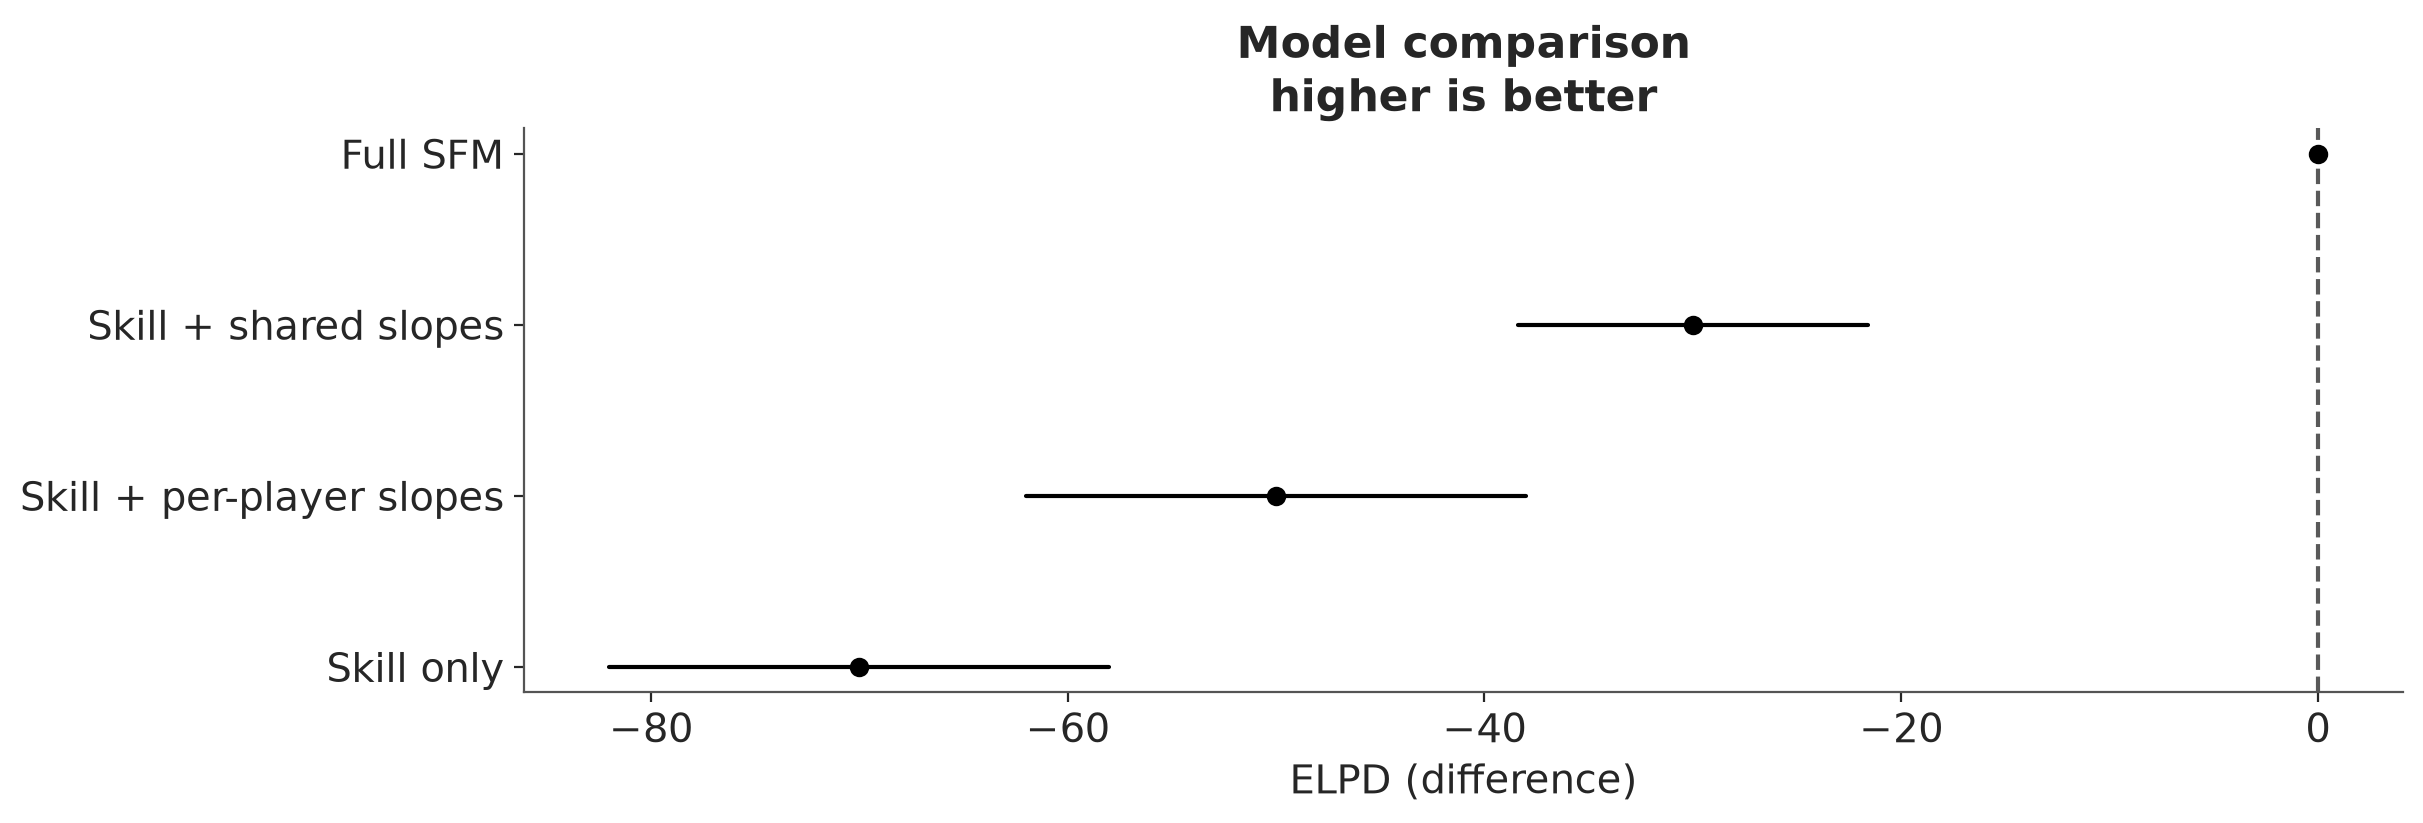

In [43]:
models = {
    "Skill only": idata_simple,
    "Skill + shared slopes": idata_shared_slopes,
    "Skill + per-player slopes": idata_per_player_slopes,
    "Full SFM": idata_sfm,
}
comparison = azs.compare(models)
azp.plot_compare(comparison, figure_kwargs={"figsize": (12, 4)})
comparison

The full SFM comes out on top, then the shared slopes, the per-player slopes, and the skill-only model last. `elpd_diff` and `dse` compare each model to the top one: the shared slopes, for instance, sit about 30 points behind the full SFM, give or take about 8. So team factors and GPs both help... to predict *one left-out match from the seasons we trained on*.

Two traps I often see students and practitioners fall into, though:
1. **ELPD is one input among several**, not a verdict: no magic threshold on a difference tells you which model is "true".
2. **LOO-CV answers a specific question**: "how well do you predict one match, knowing all the others?" Is that the question you actually care about? Let's check with the seasons we kept aside...

## Predicting each player's last season

Now the real test: each player's **last season** in our data, that no model has seen. For every one of those matches, each model gives a scoring probability (its posterior mean, i.e the proper Bayesian predictive probability).

We score them with two classic metrics, against a simple baseline: **each player's historical scoring rate**, i.e his raw rate on the training seasons:
- **Log score**: average log-probability the model gave to what actually happened (higher is better)
- **Brier score**: average squared error of the probability (lower is better)

A player's matches aren't independent from one another, so the ± below are standard errors **clustered by player**.

In [44]:
test_inputs = {
    "player_id": pd.Categorical(test_data["player"], categories=players).codes,
    "gameday_id": test_data["matchday"].to_numpy() - 1,
    "season_id": test_data["season_nbr"].to_numpy(),
    "factor_data": standardize_factors(test_data).to_numpy(),
    "goals_obs": np.zeros(len(test_data), dtype=int),  # placeholder, just for the shape
}
assert (test_inputs["player_id"] >= 0).all(), "every test player must be in the training set"
assert test_inputs["season_id"].max() < len(seasons), "every test season must be on the GP grid"


def predict_last_season(model, idata):
    """Posterior predictive scoring probabilities and goals for each player's last-season matches"""
    with model:
        pm.set_data(
            {name: value for name, value in test_inputs.items() if name in model.named_vars},
            coords={"obs_id": test_data.index},
        )
        pred = pm.sample_posterior_predictive(idata, var_names=["p", "goals_scored"], predictions=True, random_seed=rng)
    return pred.predictions


predictions = {
    "Skill only": predict_last_season(hierarchical_model, idata_simple),
    "Skill + shared slopes": predict_last_season(shared_slopes_model, idata_shared_slopes),
    "Skill + per-player slopes": predict_last_season(per_player_slopes_model, idata_per_player_slopes),
    "Full SFM": predict_last_season(SFM, idata_sfm),
}

Sampling: [goals_scored]


Output()

Sampling: [goals_scored]


Output()

Sampling: [goals_scored]


Output()

Sampling: [goals_scored]


Output()

In [45]:
scored = test_data["goal"].to_numpy()
forecasts = {name: pred["p"].mean(("chain", "draw")).to_numpy() for name, pred in predictions.items()}
forecasts["Baseline: historical rate"] = test_data["player"].map(player_stats["scoring_rate"]).to_numpy()

print(f"Players actually scored in {scored.mean():.1%} of these matches")

# log score of each match under each model
log_scores = {name: stats.bernoulli.logpmf(scored, p) for name, p in forecasts.items()}


def log_score_difference(name, reference):
    """Mean log-score difference per match between two forecasts, ± a standard error clustered by player"""
    difference = log_scores[name] - log_scores[reference]
    fit = sm.OLS(difference, np.ones(len(difference))).fit(
        cov_type="cluster", cov_kwds={"groups": test_inputs["player_id"]}
    )
    return f"{fit.params[0]:+.4f} ± {fit.bse[0]:.4f}"


pd.DataFrame(
    {
        "log score": {name: score.mean() for name, score in log_scores.items()},
        "vs historical rate": {name: log_score_difference(name, "Baseline: historical rate") for name in forecasts},
        "vs shared slopes": {name: log_score_difference(name, "Skill + shared slopes") for name in forecasts},
        "Brier score": {name: brier_score_loss(scored, p) for name, p in forecasts.items()},
        "average forecast": {name: p.mean() for name, p in forecasts.items()},
    }
).round(4)

Players actually scored in 30.4% of these matches


,log score,vs historical rate,vs shared slopes,Brier score,average forecast
Skill only,-0.5891,-0.0036 ± 0.0027,-0.0100 ± 0.0047,0.2015,0.3900
Skill + shared slopes,-0.5791,+0.0064 ± 0.0056,+0.0000 ± 0.0000,0.1972,0.3815
Skill + per-player slopes,-0.5793,+0.0062 ± 0.0071,-0.0002 ± 0.0063,0.1964,0.3768
Full SFM,-0.5980,-0.0125 ± 0.0087,-0.0189 ± 0.0057,0.2055,0.4200
Baseline: historical rate,-0.5856,+0.0000 ± 0.0000,-0.0064 ± 0.0056,0.2008,0.3865


Plot twist! On players' last seasons, **the ranking flips**: the full SFM now does *worse* than the very same model without GPs (shared slopes), by about three standard errors, and it doesn't beat simply using each player's historical rate. The per-player slopes don't lose here either: on 530 matches, the hold-out is too small to see a gap that LOO-CV measured on 7,000.

Also look at the "average forecast" column: players scored in about 30% of these matches, but **every forecast over-predicts**, even the baseline, and the full SFM the most.

What happened? **A player's last season in our data is not a random season**. For many, it's the one where they declined and left these leagues (Henry's last season at Barcelona, Suárez's last at Atlético...), and our models never trained on any player's final season in the data. Careful though: for 7 of our 27 players (Kane, Haaland, Salah...), the "last season" is just 2023/24, where our data stops, so this test mixes both situations.

Our best guess for why the GPs hurt: the career-stage curve climbs over the first seasons a player spends in these leagues, and part of that climb is probably **survivorship**: players who improve stay, players who decline leave, so the seasons we observe are tilted toward improvement. The curve then adds a bonus exactly where players are actually declining.

How would you fix that? The most principled way is to **model the exit itself**: add a second outcome, "is the player still in these leagues next season?", driven by the same skill and form, and sample both together. The model then knows *why* players disappear from the data, so their missing seasons stop biasing the career curve.

A quicker step in the same direction: right now, the career-stage GP is **one curve shared by all players**. Instead, give each player his own career curve, partially pooled around the shared one, and use **age** instead of seasons in the data. That way, the stars who last 15 seasons stop defining everybody's curve.

The lesson: **validate on the question you'll actually ask**. LOO-CV says "the GPs help to predict a match from seasons we know"; the hold-out says "they don't help to forecast a player's final season". Both are true; they just answer different questions.

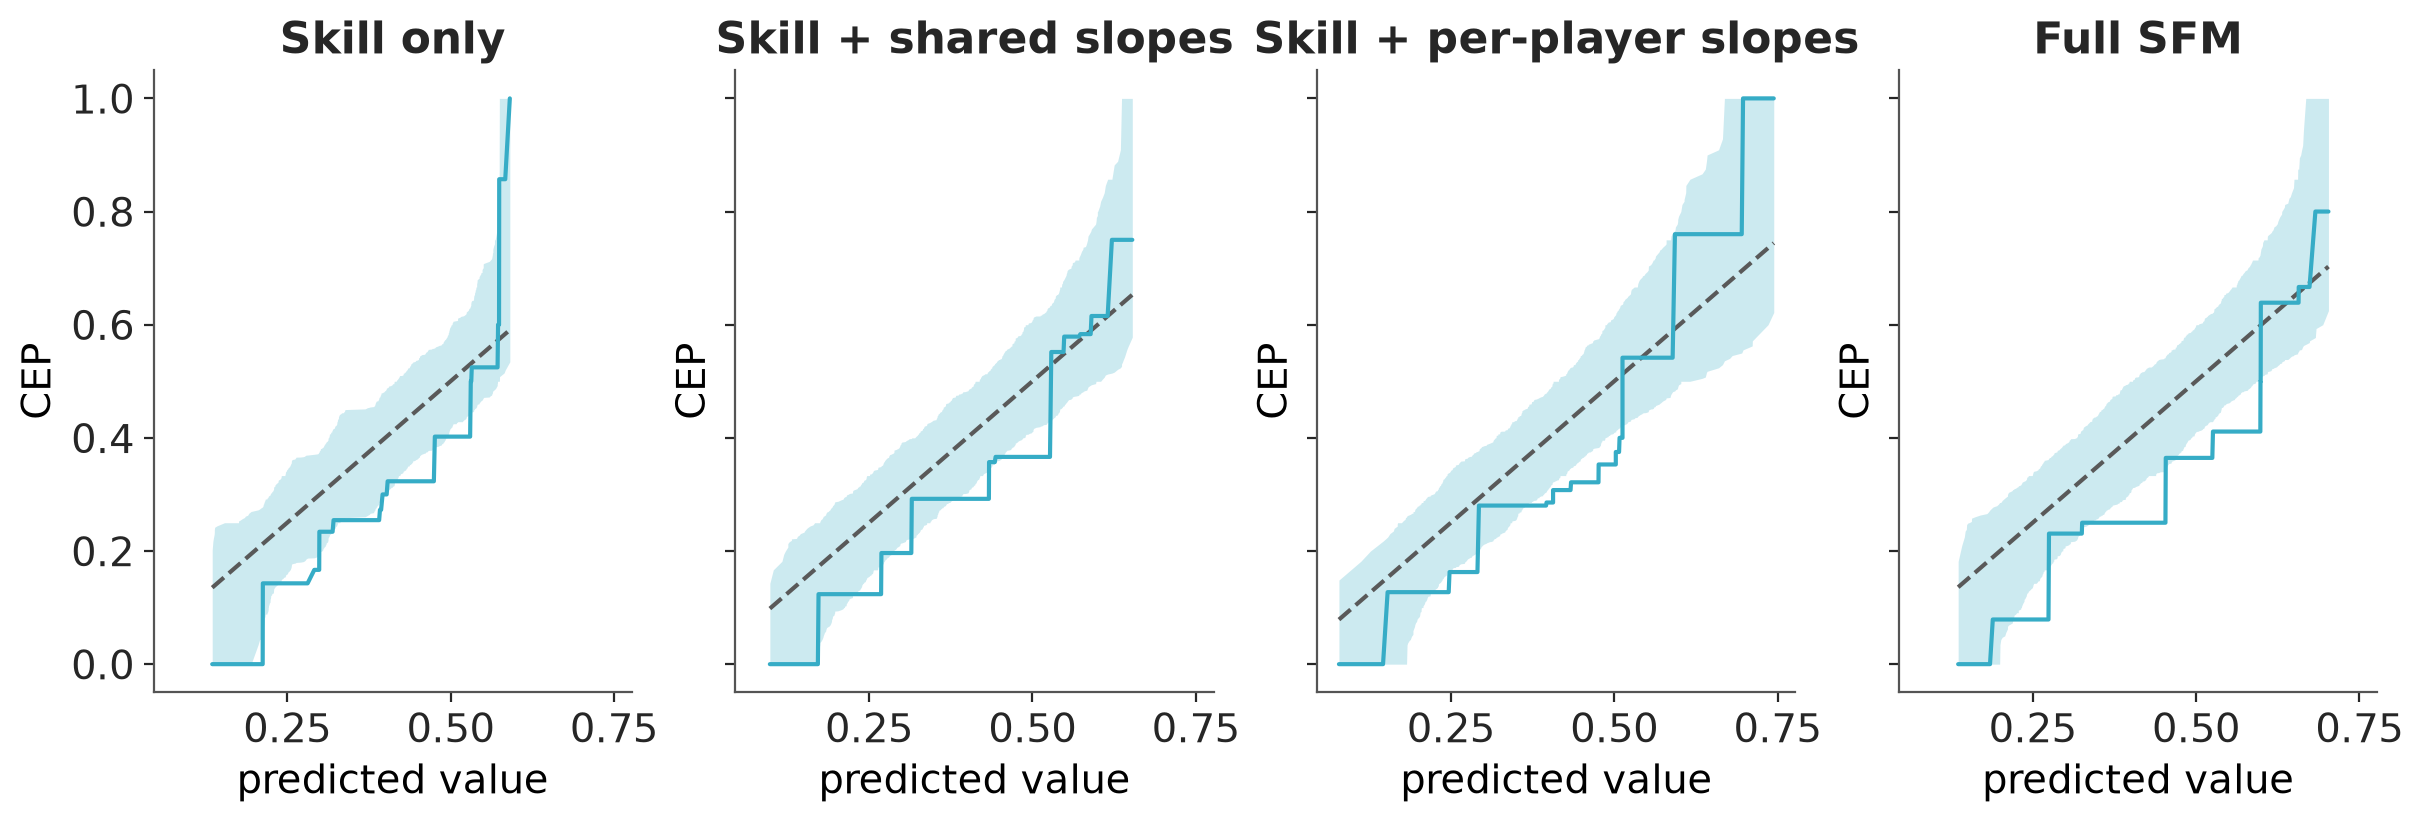

In [46]:
# Calibration on the matches no model has seen
unseen = az.from_dict(
    {
        "posterior_predictive": {name: pred["goals_scored"].to_numpy() for name, pred in predictions.items()},
        "observed_data": {name: scored for name in predictions},
    }
)
azp.plot_ppc_pava(unseen, figure_kwargs={"figsize": (12, 4), "sharex": True, "sharey": True});

Same story from another angle: on these unseen seasons, the curves mostly sit **below** the diagonal. When a model says "50% chance he scores", players scored less often than that, i.e the models **over-estimate** scoring in players' final seasons, the full SFM most clearly.

---
# Part 6 — Lessons & Open Discussion

## Communicating Uncertainty to Decision Makers

From building production probabilistic systems (at the Miami Marlins and elsewhere), here's what works:

1. **Lead with analogy, not equations.** "Think of it like a weather forecast" beats "this is a posterior distribution."

2. **Show uncertainty as a feature.** "We're 90% sure he's better than average" is more actionable than "his expected goals are 0.23."

3. **Make the output a decision tool.** SAR > PAR means "this player is a bargain": that's something a sporting director can act on.

4. **Validate publicly.** The live platform at [soccerfactormodel.com](https://www.soccerfactormodel.com) lets anyone check our work.

## What We Covered Today

- **Bayesian thinking**: Prior → Likelihood → Posterior, with uncertainty as a first-class citizen
- **Hierarchical models**: Sharing information across players via partial pooling
- **Gaussian Processes**: Modeling smooth temporal dynamics at multiple scales
- **Factor Models**: Separating individual skill from team context
- **Validation**: in-sample fit rewards complexity, cross-validation rewards signal, and you should validate on the question you'll actually ask

## Resources

- [Paper: The Soccer Factor Model](https://arxiv.org/abs/2412.05911)
- [Live Platform](https://www.soccerfactormodel.com)
- [Learning Bayesian Statistics Podcast](https://learnbayesstats.com)
- [Bayesian workflow skills for AI coding assistants](https://github.com/Learning-Bayesian-Statistics/baygent-skills)
- Video tutorial: [Mastering Gaussian Processes with PyMC](https://github.com/AlexAndorra/advanced-gp-pydata/tree/main)
- Gaussian Processes: [HSGP Reference & First Steps](https://www.pymc.io/projects/examples/en/latest/gaussian_processes/HSGP-Basic.html)
- Gaussian Processes: [HSGP Advanced Usage](https://www.pymc.io/projects/examples/en/latest/gaussian_processes/HSGP-Advanced.html)
- Faster sampling: [nutpie's low-rank mass-matrix adaptation](https://learnbayesstats.com/episode/faster-sampling-mass-matrix-adaptation-hmc-nutpie-seyboldt-carlson)

## Open Discussion

Some questions to kick things off:

- What problems are you working on where uncertainty quantification would help?
- What data sources do you have that could feed into models like these?
- Where do you find it hardest to communicate model outputs to decision makers?
- Are there specific topics (causal inference, time series, model validation) you'd like to dig into?

---

Thank you so much for coming! Everything here is at [github.com/AlexAndorra/cmsac-2026](https://github.com/AlexAndorra/cmsac-2026), and the podcast is at [learnbayesstats.com](https://learnbayesstats.com).

Best Bayesian wishes 🖖

**Alexandre Andorra** · [alexandorra.github.io](https://alexandorra.github.io/) · [LinkedIn](https://www.linkedin.com/in/alex-andorra/)